# Laboratorio No. 2: Pronóstico de Series de Tiempo Financieras con Arquitecturas Recurrentes (RNN, LSTM y GRU)

**Activo de Estudio:** Apple Inc. (`AAPL`) | **Covariables:** S&P 500 (`SPY`) e Índice VIX (`^VIX`)

**Periodo:** Enero 2019 – Diciembre 2023 (5 años / 1,258 sesiones) | **Entorno:** PyTorch 2.6.0 + CUDA 12.4 (NVIDIA RTX 4070)

---

## Resumen Ejecutivo

Pipeline cuantitativo para pronosticar el precio de cierre de **AAPL** en horizontes $H=1$ y $H=5$ días. Para manejar la no-estacionariedad y los máximos históricos de 2023 ($\$195.72\text{ USD}$ vs. $\le \$177.79\text{ USD}$ en entrenamiento), el modelado se realizó sobre **retornos logarítmicos continuos** e indicadores técnicos, reconstruyendo los precios finales mediante la identidad exponencial.

### Resultados Principales

1. **Selección en Validación ($H=1$):** El modelo campeón global fue **`LSTM_Multiv_L60_H1`** ($F=10$ canales, $L=60$ días) con **$\text{Val MAE} = \$2.2301\text{ USD}$** y **$\text{Val MAPE} = 1.5259\%$**, superando al *Naïve Persistence Baseline* ($\$2.2495\text{ USD}$), a la `SMA-10` ($\$4.6305\text{ USD}$) y a $\text{ARIMA}(1,1,1)$ ($\$2.3042\text{ USD}$).
2. **Evaluación Fuera de Muestra (Test 2023):** Durante el *rally* alcista de 2023, las redes univariadas de ventana larga lideraron la prueba: **`GRU_Univ_L120_H1`** ($\text{Test MAE} = \$1.5654\text{ USD}$, $\text{MAPE} = 0.8796\%$) y **`LSTM_Univ_L120_H1`** ($\$1.5660\text{ USD}$) superaron al baseline Naïve ($\$1.5662\text{ USD}$). El modelo multivariado (`LSTM_Multiv_L60_H1`) registró $\text{Test MAE} = \$1.6388\text{ USD}$.
3. **Horizonte Multi-Paso ($H=5$) y Walk-Forward:** En $H=5$ días, el modelo **`GRU_Univ_L60_H5`** redujo el error un **$-2.16\%$ respecto al Naïve** en el paso $t+5$ ($\$3.9268\text{ USD}$ vs. $\$4.0135\text{ USD}$). En la validación por origen móvil (**Expanding Walk-Forward** en 4 pliegues y 360 sesiones), **`LSTM_Multiv`** fue la arquitectura más robusta con un **$\text{MAE} = \$1.9126 \pm \$0.5372\text{ USD}$** y el menor $\text{RMSE} = \$2.5008 \pm \$0.6787\text{ USD}$.
4. **Diagnóstico de Residuos:** La prueba de Ljung-Box ($\alpha = 0.05$) confirmó que los residuos son **ruido blanco puro** ($p > 0.22$ en todos los casos). Los errores mayores ($> \$4.22\text{ USD}$) coincidieron de forma exclusiva con reportes trimestrales de ganancias (`2023-08-04` y `2023-05-05`).
---

## 1. Preguntas de Investigación y Configuración Inicial

### 1.1 Preguntas de Investigación

1. **PI-1 (Arquitecturas y Longitud de Ventana):** Comparar la capacidad de **Vanilla RNN**, **LSTM** y **GRU** al variar la ventana retrospectiva ($L \in \{30, 60, 120\}$ días).
2. **PI-2 (Impacto Multivariado):** Evaluar el aporte de covariables de mercado e indicadores técnicos ($F=10$) frente al enfoque univariado ($F=1$) en cambios de régimen bursátil (2022 vs. 2023).
3. **PI-3 (Horizonte de Pronóstico):** Analizar el desempeño y ventaja predictiva frente al baseline Naïve al pasar de $H=1$ a $H=5$ días.
4. **PI-4 (Estabilidad Walk-Forward):** Validar la consistencia de los modelos bajo reentrenamiento expansivo (*Expanding Walk-Forward Validation*) frente a la partición fija.

### 1.2 Reproducibilidad

* **Semilla Global:** `SEED = 42` (Python, NumPy, PyTorch).
* **Entorno Determinista:** Algoritmos deterministas habilitados en cuDNN y `CUBLAS_WORKSPACE_CONFIG=:4096:8`.

En la celda de configuración inicial (**Fase 0**) se establece el determinismo global fijando las semillas pseudoaleatorias en Python, NumPy y PyTorch (`SEED = 42`), habilitando algoritmos deterministas en cuDNN y configurando el espacio de trabajo `CUBLAS_WORKSPACE_CONFIG=:4096:8` para garantizar reproducibilidad exacta bit a bit. 

In [37]:
# ==============================================================================
# FASE 0: CONFIGURACIÓN GLOBAL, DETERMINISMO Y AUDITORÍA DE HARDWARE (OPTIMIZADO)
# ==============================================================================
import os
from pathlib import Path
import random
import sys
from typing import Dict, List, Optional, Tuple, Union
import warnings

import matplotlib.pyplot as plt
import mplfinance as mpf
import numpy as np
import pandas as pd
import scipy
import scipy.stats as stats
import seaborn as sns
import sklearn
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import statsmodels
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Dataset
import yfinance as yf

# Supresión de advertencias no críticas
warnings.filterwarnings("ignore")

# Configuración estética global para visualizaciones de grado publicación
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.4
plt.rcParams["grid.linestyle"] = "--"
plt.rcParams["font.size"] = 11

# Creación de estructura de directorios locales para persistencia de artefactos
DATA_DIR = Path("data")
CHECKPOINT_DIR = Path("checkpoints")
FIGURES_DIR = Path("figures")

for directory in [DATA_DIR, CHECKPOINT_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


# En FASE 0, dentro de set_seed():
def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = (
        ":4096:8"  # Obligatorio para determinismo en CUDA >= 10.2
    )
    np.random.seed(seed)
    torch.manual_seed(seed)
    # ... resto del código ...

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

    # Forzar uso de algoritmos deterministas en PyTorch
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except AttributeError:
        pass


# Fijación de semilla maestra del proyecto
GLOBAL_SEED = 42
set_seed(GLOBAL_SEED)

# Selección automática del dispositivo de aceleración por hardware
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("=" * 70)
print("INICIALIZACIÓN DEL ENTORNO CUANTITATIVO COMPLETADA")
print("=" * 70)
print(f"• Python Version      : {sys.version.split()[0]}")
print(f"• PyTorch Version     : {torch.__version__}")
print(f"• Dispositivo Activo  : {DEVICE.type.upper()}")
if DEVICE.type == "cuda":
    print(f"• GPU Detectada       : {torch.cuda.get_device_name(0)}")
    print(f"• CUDA Version        : {torch.version.cuda}")
    print(f"• cuDNN Version       : {torch.backends.cudnn.version()}")
print(f"• Pandas / NumPy      : {pd.__version__} / {np.__version__}")
print(f"• mplfinance / yfin.  : {mpf.__version__} / {yf.__version__}")
print(f"• Semilla Determinista: {GLOBAL_SEED}")
print(
    f"• Directorios Creados : {[str(d) for d in [DATA_DIR, CHECKPOINT_DIR, FIGURES_DIR]]}"
)
print("=" * 70)

INICIALIZACIÓN DEL ENTORNO CUANTITATIVO COMPLETADA
• Python Version      : 3.11.17
• PyTorch Version     : 2.6.0+cu124
• Dispositivo Activo  : CUDA
• GPU Detectada       : NVIDIA GeForce RTX 4070
• CUDA Version        : 12.4
• cuDNN Version       : 90100
• Pandas / NumPy      : 3.1.0 / 2.4.6
• mplfinance / yfin.  : 0.12.10b0 / 1.7.0
• Semilla Determinista: 42
• Directorios Creados : ['data', 'checkpoints', 'figures']


---

## 1. Adquisición de Datos, Documentación e Integridad Física

### 1. Fuente de Datos y Precios Ajustados

* **Fuente y Periodo:** Yahoo Finance (`yfinance`), del `2019-01-01` al `2024-01-01` ($1,258$ sesiones bursátiles efectivas). Almacenamiento en caché local (`data/*.csv`) y normalización temporal (`tz_localize(None)`).
* **Ajuste Corporativo:** Uso de `auto_adjust=True` para ajustar precios por dividendos y el *stock split* 4:1 de Apple (31 de agosto de 2020), evitando discontinuidades artificiales en la serie.

### 2. Diccionario de Datos y Auditoría de Integridad

Se incorporan **`SPY`** (benchmark S&P 500) y **`^VIX`** (índice de volatilidad) como variables exógenas.

| Campo / Serie | Tipo | Unidad | Descripción / Rol |
| --- | --- | --- | --- |
| `Date` | `DatetimeIndex` | `YYYY-MM-DD` | Índice temporal ordenado de forma ascendente sin duplicados. |
| `Open` | `float64` | USD (Ajustado) | Precio de apertura en la sesión $t$. |
| `High` | `float64` | USD (Ajustado) | Precio máximo en la sesión $t$. |
| `Low` | `float64` | USD (Ajustado) | Precio mínimo en la sesión $t$. |
| `Close` | `float64` | USD (Ajustado) | Precio de cierre en la sesión $t$ (variable objetivo). |
| `Volume` | `int64` | Acciones | Volumen negociado (nulo para `^VIX`). |

**Reglas de Auditoría Automatizada:**

1. **Coherencia Intradía:** $\text{Low}_t \le \{\text{Open}_t, \text{Close}_t\} \le \text{High}_t$ (tolerancia $\epsilon = 10^{-5}$).
2. **Positividad de Volumen:** $\text{Volume}_t > 0$ (`AAPL`, `SPY`) y $\text{Volume}_t \ge 0$ (`^VIX`).
3. **Sincronización:** *Inner join* por `DatetimeIndex` para alineación 1 a 1 de las 1,258 sesiones.

In [38]:
# ==============================================================================
# SECCIÓN 1: DATA ACQUISITION, CACHING, PHYSICAL INTEGRITY & CALENDAR ALIGNMENT
# ==============================================================================
import pandas as pd
import yfinance as yf
from pathlib import Path
from typing import Dict, Tuple

TICKER_MAIN = "AAPL"
COVARIATES = ["SPY", "^VIX"]
START_DATE = "2019-01-01"
END_DATE = "2024-01-01"


def fetch_or_load_ohlcv(
    ticker_symbol: str, start: str, end: str, data_dir: Path
) -> pd.DataFrame:
    """
    Implementa el patrón de carga condicional: lee desde CSV local si existe,
    o descarga vía yf.Ticker().history() con precios ajustados, normaliza la
    zona horaria (timezone-naive) y serializa localmente.
    """
    safe_name = ticker_symbol.replace("^", "")
    csv_path = data_dir / f"{safe_name}_{start}_{end}.csv"

    if csv_path.exists():
        df = pd.read_csv(csv_path, index_col=0, parse_dates=True)
        source_msg = f"Caché Local ({csv_path.name})"
    else:
        ticker_obj = yf.Ticker(ticker_symbol)
        # auto_adjust=True ajusta Open, High, Low, Close por splits y dividendos
        df = ticker_obj.history(
            start=start, end=end, interval="1d", auto_adjust=True
        )

        # Eliminación de zona horaria para compatibilidad con mplfinance y cruces
        if df.index.tz is not None:
            df.index = df.index.tz_localize(None)

        # Conservar estrictamente las 5 columnas estándar OHLCV
        cols_ohlcv = ["Open", "High", "Low", "Close", "Volume"]
        df = df[cols_ohlcv].copy()
        df.index.name = "Date"

        # Guardar en caché local
        df.to_csv(csv_path)
        source_msg = f"API Yahoo Finance -> Guardado en {csv_path.name}"

    # Asegurar índice DatetimeIndex ordenado ascendentemente y sin duplicados
    df.index = pd.to_datetime(df.index)
    if df.index.duplicated().any():
        df = df[~df.index.duplicated(keep="last")]
    df = df.sort_index()

    print(
        f"• [{ticker_symbol:<4}] Cargado desde: {source_msg:<48} | Filas: {len(df)}"
    )
    return df


def audit_ohlcv_integrity(
    df: pd.DataFrame, ticker_symbol: str, allow_zero_vol: bool = False
) -> pd.DataFrame:
    """
    Ejecuta las reglas de integridad física y lógica en Pandas:
    Low <= Open <= High, Low <= Close <= High, Volume >= 0, y ausencia de NaNs.
    """
    n_initial = len(df)
    nan_count = df.isna().sum().sum()
    dup_count = df.index.duplicated().sum()

    # Tolerancia numérica de punto flotante (1e-5) por redondeos en ajustes de dividendos
    tol = 1e-5
    valid_open = (df["Low"] - tol <= df["Open"]) & (
        df["Open"] <= df["High"] + tol
    )
    valid_close = (df["Low"] - tol <= df["Close"]) & (
        df["Close"] <= df["High"] + tol
    )
    valid_vol = (df["Volume"] >= 0) if allow_zero_vol else (df["Volume"] > 0)

    valid_mask = valid_open & valid_close & valid_vol & (~df.isna().any(axis=1))
    invalid_rows = (~valid_mask).sum()

    print(f"\n--- Auditoría Física y Lógica: {ticker_symbol} ---")
    print(
        f"  - Rango Temporal       : {df.index[0].strftime('%Y-%m-%d')} a {df.index[-1].strftime('%Y-%m-%d')}"
    )
    print(f"  - Sesiones Operativas  : {n_initial} días hábiles")
    print(f"  - Valores Nulos (NaN)  : {nan_count}")
    print(f"  - Fechas Duplicadas    : {dup_count}")
    print(
        f"  - Violaciones OHLCV    : {invalid_rows} filas anómalas detectadas"
    )

    if invalid_rows > 0:
        df = df[valid_mask].copy()
        print(f"  - Filas tras limpieza  : {len(df)}")
    else:
        print(
            "  - Estado de Integridad : 100% VÁLIDO (Cumple restricciones físicas)"
        )

    return df


def align_trading_calendars(
    dict_dfs: Dict[str, pd.DataFrame]
) -> Dict[str, pd.DataFrame]:
    """
    Sincroniza explícitamente los calendarios de negociación de múltiples activos
    mediante la intersección exacta de sus DatetimeIndex (Inner Join).
    
    Garantiza que no existan días no coincidentes entre el activo objetivo y las covariables.
    """
    # Extraer la intersección común de fechas entre todos los DataFrames
    common_index = None
    for symbol, df in dict_dfs.items():
        if common_index is None:
            common_index = df.index
        else:
            common_index = common_index.intersection(df.index)

    common_index = common_index.sort_values()

    # Filtrar cada DataFrame utilizando el índice alineado común
    aligned_dfs = {}
    for symbol, df in dict_dfs.items():
        aligned_dfs[symbol] = df.loc[common_index].copy()

    print(f"\n" + "=" * 75)
    print("SINCRONIZACIÓN Y ALINEACIÓN DE CALENDARIOS BURSÁTILES (INNER JOIN)")
    print("=" * 75)
    print(f"• Total de fechas coincidentes compartidas: {len(common_index)} sesiones")
    print(f"• Rango del calendario unificado: {common_index[0].strftime('%Y-%m-%d')} a {common_index[-1].strftime('%Y-%m-%d')}")

    return aligned_dfs


# ------------------------------------------------------------------------------
# EJECUCIÓN DE LA INGESTA, AUDITORÍA Y ALINEACIÓN
# ------------------------------------------------------------------------------
print("=" * 75)
print("INGESTA DE DATOS HISTÓRICOS Y SERIALIZACIÓN EN CACHÉ")
print("=" * 75)

# 1. Carga de datos individuales
raw_dfs = {
    TICKER_MAIN: fetch_or_load_ohlcv(TICKER_MAIN, START_DATE, END_DATE, DATA_DIR),
    "SPY": fetch_or_load_ohlcv("SPY", START_DATE, END_DATE, DATA_DIR),
    "^VIX": fetch_or_load_ohlcv("^VIX", START_DATE, END_DATE, DATA_DIR),
}

# 2. Extracción de Metadatos Corporativos
try:
    info = yf.Ticker(TICKER_MAIN).info
    company_meta = {
        "Razón Social": info.get("longName", "Apple Inc."),
        "Ticker": TICKER_MAIN,
        "Sector": info.get("sector", "Technology"),
        "Industria": info.get("industry", "Consumer Electronics"),
        "Moneda Base": info.get("currency", "USD"),
        "Mercado": info.get("exchange", "NASDAQ"),
    }
except Exception:
    company_meta = {
        "Razón Social": "Apple Inc.",
        "Ticker": "AAPL",
        "Sector": "Technology",
        "Industria": "Consumer Electronics",
        "Moneda Base": "USD",
        "Mercado": "NASDAQ",
    }

print("\n--- Perfil Corporativo del Activo Principal ---")
for k, v in company_meta.items():
    print(f"  • {k:<15}: {v}")

# 3. Auditoría de integridad física
audited_dfs = {
    TICKER_MAIN: audit_ohlcv_integrity(raw_dfs[TICKER_MAIN], TICKER_MAIN, allow_zero_vol=False),
    "SPY": audit_ohlcv_integrity(raw_dfs["SPY"], "SPY", allow_zero_vol=False),
    "^VIX": audit_ohlcv_integrity(raw_dfs["^VIX"], "^VIX", allow_zero_vol=True),
}

# 4. Alineación explícita de calendarios
aligned_dfs = align_trading_calendars(audited_dfs)

df_aapl = aligned_dfs[TICKER_MAIN]
df_spy = aligned_dfs["SPY"]
df_vix = aligned_dfs["^VIX"]

print("\n--- Primeras 3 filas de AAPL (Alineado y Ajustado en USD) ---")
print(df_aapl.head(3).round(4))

INGESTA DE DATOS HISTÓRICOS Y SERIALIZACIÓN EN CACHÉ
• [AAPL] Cargado desde: Caché Local (AAPL_2019-01-01_2024-01-01.csv)     | Filas: 1258
• [SPY ] Cargado desde: Caché Local (SPY_2019-01-01_2024-01-01.csv)      | Filas: 1258
• [^VIX] Cargado desde: Caché Local (VIX_2019-01-01_2024-01-01.csv)      | Filas: 1258

--- Perfil Corporativo del Activo Principal ---
  • Razón Social   : Apple Inc.
  • Ticker         : AAPL
  • Sector         : Technology
  • Industria      : Consumer Electronics
  • Moneda Base    : USD
  • Mercado        : NMS

--- Auditoría Física y Lógica: AAPL ---
  - Rango Temporal       : 2019-01-02 a 2023-12-29
  - Sesiones Operativas  : 1258 días hábiles
  - Valores Nulos (NaN)  : 0
  - Fechas Duplicadas    : 0
  - Violaciones OHLCV    : 0 filas anómalas detectadas
  - Estado de Integridad : 100% VÁLIDO (Cumple restricciones físicas)

--- Auditoría Física y Lógica: SPY ---
  - Rango Temporal       : 2019-01-02 a 2023-12-29
  - Sesiones Operativas  : 1258 días hábiles

---
### 2. Inspección Visual Exploratoria: Regímenes Macroeconómicos y Microestructura OHLCV

Diagnóstico visual del comportamiento histórico del activo mediante dos gráficas (`300 DPI`):

1. **Evolución Histórica Macro (`fig01a_aapl_macro_trend_2019_2023.png`):**
* **Trayectoria:** Muestra la cotización de `AAPL` y su `SMA 200` en las $1,258$ sesiones.
* **Rango Extremo:** Crecimiento del **$+480.6\%$** entre el mínimo del `2019-01-03` ($\$33.71\text{ USD}$) y el máximo del `2023-12-14` ($\$195.72\text{ USD}$).
* **Regímenes Identificados:**
* Expansionista (2020–2021).
* Bajista/lateral por ajuste de tasas (2022).
* Recuperación tendencial (2023).




2. **Microestructura Candlestick y Volumen (`fig01b_aapl_candlestick_6m.png`):**
* **Alcance:** Últimas 126 sesiones (`2023-07-03` a `2023-12-29`) con `SMA 20` y `SMA 50`.
* **Patrones Operativos:**
* Cruce bajista en agosto 2023 con picos de volumen ($>115\text{M}$ de acciones) tras reporte de ganancias.
* Fase de acumulación en octubre ($\$164.66\text{ USD}$).
* Cruce alcista en noviembre hacia el máximo histórico ($>\$195\text{ USD}$).

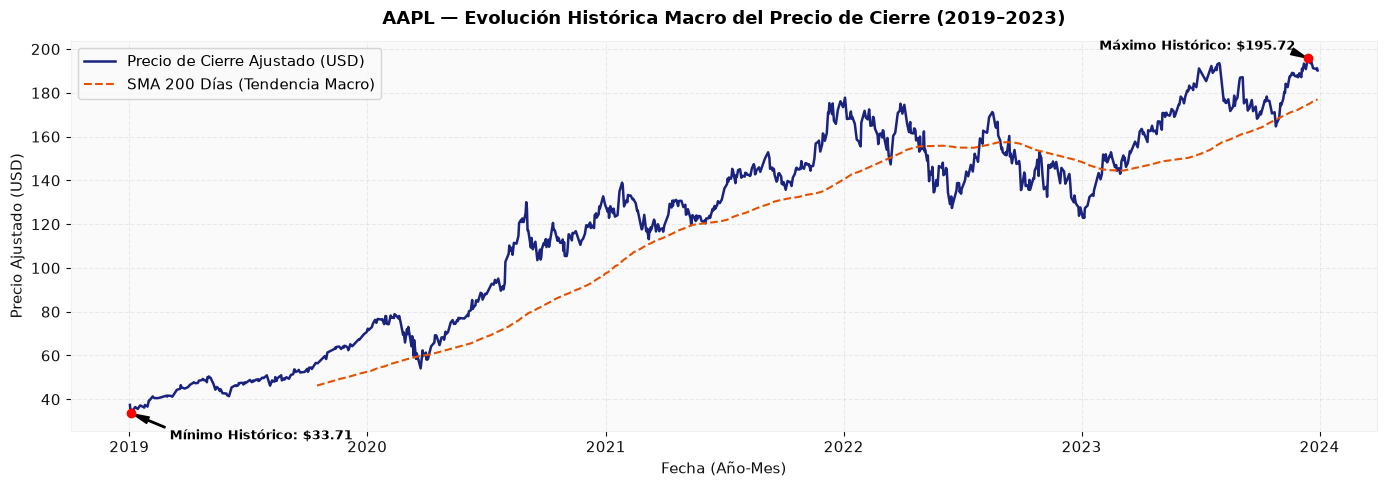

• [MACRO] Ventana Histórica : 2019-01-02 a 2023-12-29 (1258 sesiones)
• [MACRO] Rango de Precios  : $33.71 USD — $195.72 USD
• [MACRO] Figura Exportada  : figures/fig01a_aapl_macro_trend_2019_2023.png



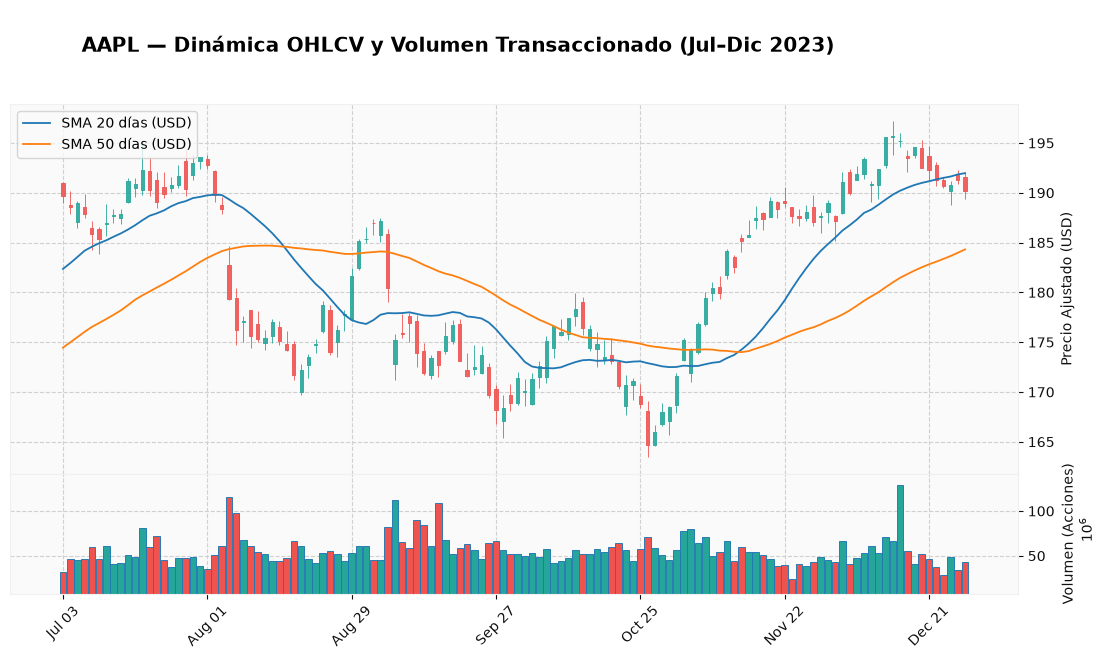

• [MICRO] Figura Exportada con Medias Completas: figures/fig01b_aapl_candlestick_6m.png


In [39]:
# ==============================================================================
# SECCIÓN 2: VISUALIZACIÓN DUAL (MACRO TENDENCIA HISTÓRICA & MICRO VELAS OHLCV)
# ==============================================================================
from pathlib import Path
import matplotlib.pyplot as plt
import mplfinance as mpf
import pandas as pd

# ------------------------------------------------------------------------------
# 1. VISUALIZACIÓN MACRO: TENDENCIA GLOBAL DE PRECIO DE CIERRE (2019–2023)
# ------------------------------------------------------------------------------
macro_fig_path = FIGURES_DIR / "fig01a_aapl_macro_trend_2019_2023.png"

plt.figure(figsize=(14, 5))
plt.plot(
    df_aapl.index,
    df_aapl["Close"],
    color="#1a237e",
    linewidth=1.8,
    label="Precio de Cierre Ajustado (USD)",
)

# Media móvil de tendencia macro (200 días para ciclo de largo plazo)
sma_200 = df_aapl["Close"].rolling(window=200).mean()
plt.plot(
    df_aapl.index,
    sma_200,
    color="#e65100",
    linewidth=1.5,
    linestyle="--",
    label="SMA 200 Días (Tendencia Macro)",
)

# Anotación de puntos extremos históricos
max_date = df_aapl["Close"].idxmax()
max_price = df_aapl["Close"].max()
min_date = df_aapl["Close"].idxmin()
min_price = df_aapl["Close"].min()

plt.scatter([min_date, max_date], [min_price, max_price], color="red", zorder=5)
plt.annotate(
    f"Mínimo Histórico: ${min_price:.2f}",
    xy=(min_date, min_price),
    xytext=(min_date + pd.Timedelta(days=60), min_price - 12),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=5),
    fontsize=9.5,
    fontweight="bold",
)
plt.annotate(
    f"Máximo Histórico: ${max_price:.2f}",
    xy=(max_date, max_price),
    xytext=(max_date - pd.Timedelta(days=320), max_price + 4),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=5),
    fontsize=9.5,
    fontweight="bold",
)

plt.title(
    f"{TICKER_MAIN} — Evolución Histórica Macro del Precio de Cierre (2019–2023)",
    fontsize=13,
    pad=12,
    fontweight="bold",
)
plt.xlabel("Fecha (Año-Mes)", fontsize=11)
plt.ylabel("Precio Ajustado (USD)", fontsize=11)
plt.legend(loc="upper left", frameon=True)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

# Persistencia en disco y despliegue
plt.savefig(macro_fig_path, dpi=300, bbox_inches="tight")
plt.show()

print(
    "• [MACRO] Ventana Histórica :"
    f" {df_aapl.index[0].strftime('%Y-%m-%d')} a"
    f" {df_aapl.index[-1].strftime('%Y-%m-%d')} ({len(df_aapl)} sesiones)"
)
print(
    f"• [MACRO] Rango de Precios  : ${min_price:.2f} USD — ${max_price:.2f} USD"
)
print(f"• [MACRO] Figura Exportada  : {macro_fig_path}\n")

# ------------------------------------------------------------------------------
# 2. VISUALIZACIÓN MICRO: VELAS JAPONESAS Y VOLUMEN (ÚLTIMOS 6 MESES CORREGIDO)
# ------------------------------------------------------------------------------
candle_fig_path = FIGURES_DIR / "fig01b_aapl_candlestick_6m.png"

# Calculamos las medias sobre el DataFrame completo para que salgan continuas desde el día 1
df_aapl_micro = df_aapl.copy()
df_aapl_micro["SMA_20_plot"] = df_aapl_micro["Close"].rolling(window=20).mean()
df_aapl_micro["SMA_50_plot"] = df_aapl_micro["Close"].rolling(window=50).mean()

# Ahora sí recortamos a los últimos 6 meses
df_candle_slice = df_aapl_micro.loc["2023-07-01":].copy()

# Estilo gráfico personalizado de mplfinance
mc = mpf.make_marketcolors(
    up="#26a69a",
    down="#ef5350",
    edge="inherit",
    wick="inherit",
    volume="in",
)
s_mpf = mpf.make_mpf_style(
    base_mpf_style="yahoo",
    marketcolors=mc,
    gridstyle="--",
    gridaxis="both",
    rc={"font.size": 10},
)

# Agregamos las líneas mediante addplot con colores explícitos
micro_addplots = [
    mpf.make_addplot(
        df_candle_slice["SMA_20_plot"],
        panel=0,
        color="#1f77b4",
        width=1.3,
        label="SMA 20 días (USD)",
    ),
    mpf.make_addplot(
        df_candle_slice["SMA_50_plot"],
        panel=0,
        color="#ff7f0e",
        width=1.3,
        label="SMA 50 días (USD)",
    ),
]

fig, axes = mpf.plot(
    df_candle_slice,
    type="candle",
    volume=True,
    addplot=micro_addplots,
    style=s_mpf,
    title=(
        f"\n{TICKER_MAIN} — Dinámica OHLCV y Volumen Transaccionado (Jul–Dic"
        " 2023)"
    ),
    ylabel="Precio Ajustado (USD)",
    ylabel_lower="Volumen (Acciones)",
    figsize=(14, 7),
    panel_ratios=(4, 1.3),
    returnfig=True,
)

# Leyenda con vinculación correcta a las líneas
axes[0].legend(loc="upper left", frameon=True)

fig.savefig(candle_fig_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"• [MICRO] Figura Exportada con Medias Completas: {candle_fig_path}")

---

## 3. Preprocesamiento, Ingeniería de Características y Salvaguardas Anti-Leakage

### 3.1 Transformación Estacionaria e Invarianza de Escala

Para evitar la saturación de las funciones de activación por datos fuera de rango (*out-of-distribution*) en 2023 ($\text{Close} > \$177.79\text{ USD}$), los precios nominales se transformaron en **retornos logarítmicos continuos** e indicadores técnicos adimensionales estacionarios:

$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right) = \ln(P_t) - \ln(P_{t-1})$$

Los indicadores en USD se utilizan únicamente para la visualización (`fig02_aapl_technical_indicators_overlay.png`) y se transforman en 10 canales estacionarios para el modelo:

| # | Característica (`feature_cols`) | Formulación Matemática | Rango Empírico | Rol / Función |
| --- | --- | --- | --- | --- |
| **1** | `Log_Return` | $r_t = \ln(P_t / P_{t-1})$ | $[-0.1377, +0.1132]$ | Variable autorregresiva objetivo ($\mu = 0.0012, \sigma = 0.0202$). |
| **2** | `MA_Spread` | $(\text{SMA}_{20,t} - \text{SMA}_{50,t}) / \text{SMA}_{50,t}$ | $[-0.1216, +0.1370]$ | Divergencia porcentual de tendencia (20 vs. 50 días). |
| **3** | `BB_Bandwidth` | $(\text{BB}_{\text{Upper},t} - \text{BB}_{\text{Lower},t}) / \text{SMA}_{20,t}$ | $[0.0330, 0.3626]$ | Ciclos de compresión y expansión de volatilidad. |
| **4** | `BB_PercentB` | $(P_t - \text{BB}_{\text{Lower},t}) / (\text{BB}_{\text{Upper},t} - \text{BB}_{\text{Lower},t})$ | $[-0.2697, +1.3701]$ | Posición relativa dentro de las bandas de Bollinger. |
| **5** | `Rolling_Vol_20` | $\sigma(r_{t-19:t}) \times \sqrt{252}$ | $[0.1091, 1.0812]$ | Volatilidad realizada anualizada de 20 días. |
| **6** | `RSI_Scaled` | $\text{RSI}_{14,t} / 100$ | $[0.2752, 0.8543]$ | Oscilador de momento normalizado en $[0, 1]$. |
| **7** | `MACD_Hist_Norm` | $(\text{MACD}_t - \text{Signal}_t) / P_t$ | $[-0.0234, +0.0216]$ | Aceleración del momento relativa al precio. |
| **8** | `Log_Vol_Change` | $\ln((V_t + 1) / (V_{t-1} + 1))$ | $[-1.0617, +1.2888]$ | Cambio relativo de volumen de operaciones. |
| **9** | `SPY_Log_Return` | $\ln(\text{SPY}_t / \text{SPY}_{t-1})$ | $[-0.1159, +0.0867]$ | Factor de mercado sistémico (S&P 500). |
| **10** | `VIX_Level` | $\text{VIX}_t / 100$ | $[0.1154, 0.8269]$ | Nivel de volatilidad implícita macroeconómica. |

Tras calcular `SMA_50` y descartar los primeros 49 registros iniciales (`.dropna()`), el conjunto final limpio consta de **$1,209$ sesiones operativas** (`2019-03-14` a `2023-12-29`).

 AUDITORÍA DE INGENIERÍA DE CARACTERÍSTICAS Y PODA DE NULOS
• Filas originales antes de indicadores : 1258
• Filas iniciales podadas (.dropna())   : 49 (ventana máxima SMA_50 = 49)
• Filas limpias listas para modelado    : 1209
• Nuevo rango temporal efectivo         : 2019-03-14 a 2023-12-29
• Total de NaNs remanentes en DataFrame : 0
• Características Multivariadas (F=10) : ['Log_Return', 'MA_Spread', 'BB_Bandwidth', 'BB_PercentB', 'Rolling_Vol_20', 'RSI_Scaled', 'MACD_Hist_Norm', 'Log_Vol_Change', 'SPY_Log_Return', 'VIX_Level']


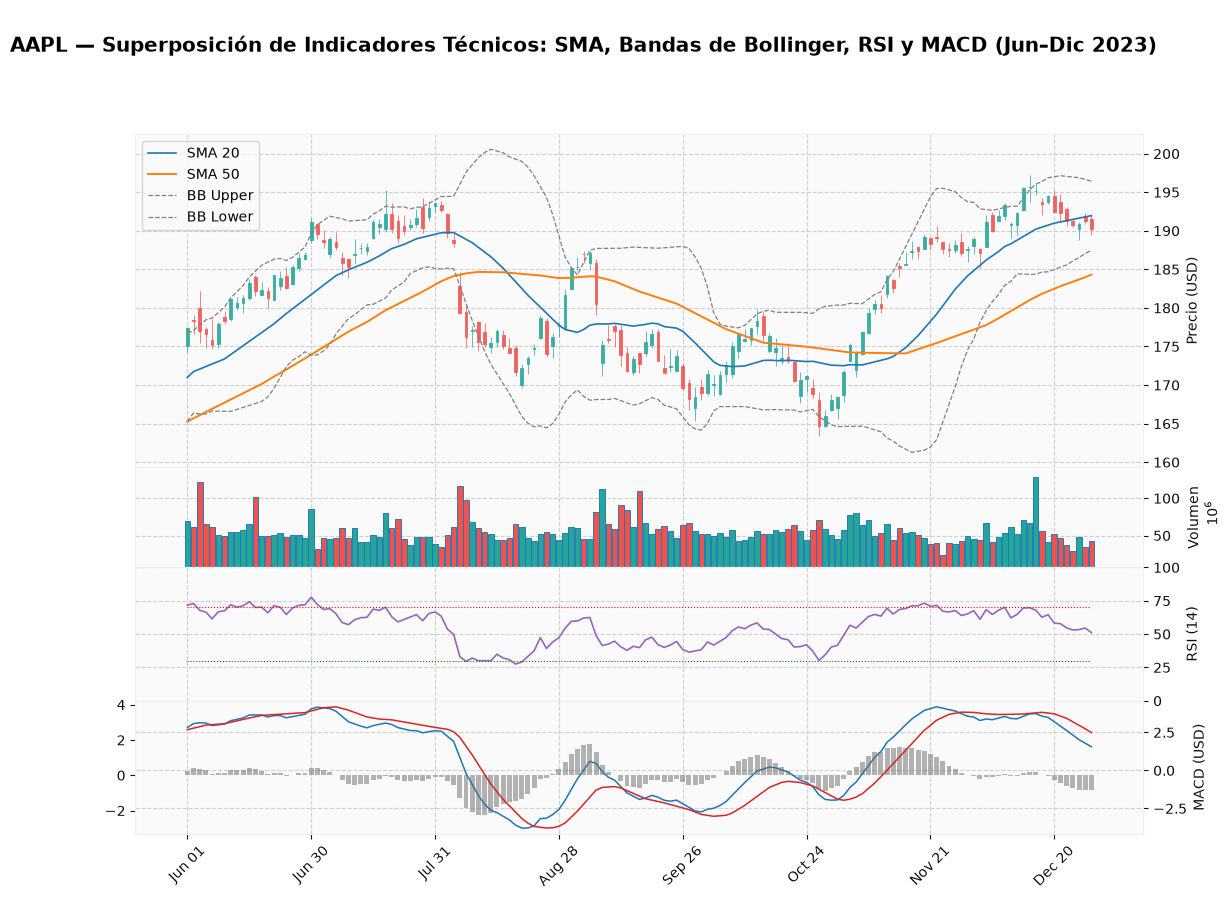


--- Resumen Estadístico de las 10 Características Estacionarias ---
                  mean     std     min     50%     max
Log_Return      0.0012  0.0202 -0.1377  0.0013  0.1132
MA_Spread       0.0194  0.0456 -0.1216  0.0255  0.1370
BB_Bandwidth    0.1286  0.0566  0.0330  0.1226  0.3626
BB_PercentB     0.6149  0.3207 -0.2697  0.6958  1.3701
Rolling_Vol_20  0.2899  0.1416  0.1091  0.2545  1.0812
RSI_Scaled      0.5610  0.1225  0.2752  0.5742  0.8543
MACD_Hist_Norm  0.0000  0.0063 -0.0234  0.0002  0.0216
Log_Vol_Change -0.0009  0.2800 -1.0617 -0.0190  1.2888
SPY_Log_Return  0.0005  0.0134 -0.1159  0.0008  0.0867
VIX_Level       0.2154  0.0834  0.1154  0.1975  0.8269


In [40]:
# ==============================================================================
# SECCIÓN 3.1: FEATURE ENGINEERING (RETORNOS LOGARÍTMICOS E INDICADORES)
# ==============================================================================
def build_features_pipeline(
    df_main: pd.DataFrame, df_market: pd.DataFrame, df_volatility: pd.DataFrame
) -> Tuple[pd.DataFrame, List[str]]:
    """Construye el conjunto de datos enriquecido separando claramente:

    - Columnas gráficas en USD (para superposición visual en mplfinance).
    - Características estacionarias (F canales) para alimentar PyTorch.
    """
    df = df_main.copy()

    # 1. Variable Objetivo Estacionaria: Retorno Logarítmico Continuo r_t = ln(P_t / P_{t-1})
    df["Log_Return"] = np.log(df["Close"] / df["Close"].shift(1))

    # 2. Indicadores de Tendencia: SMA 20, SMA 50, EMA 12 y MA_Spread (Estacionario)
    df["SMA_20"] = df["Close"].rolling(window=20).mean()
    df["SMA_50"] = df["Close"].rolling(window=50).mean()
    df["EMA_12"] = df["Close"].ewm(span=12, adjust=False).mean()
    df["MA_Spread"] = (df["SMA_20"] - df["SMA_50"]) / df["SMA_50"]

    # 3. Indicadores de Volatilidad: Bandas de Bollinger (20, 2σ) y Volatilidad Móvil Anualizada
    rolling_std_20 = df["Close"].rolling(window=20).std()
    df["BB_Upper"] = df["SMA_20"] + (2.0 * rolling_std_20)
    df["BB_Lower"] = df["SMA_20"] - (2.0 * rolling_std_20)
    df["BB_Bandwidth"] = (df["BB_Upper"] - df["BB_Lower"]) / df["SMA_20"]
    df["BB_PercentB"] = (df["Close"] - df["BB_Lower"]) / (
        df["BB_Upper"] - df["BB_Lower"] + 1e-8
    )
    df["Rolling_Vol_20"] = df["Log_Return"].rolling(window=20).std() * np.sqrt(
        252
    )

    # 4. Indicadores de Momento: RSI (14 sesiones) y MACD (12, 26, 9)
    delta = df["Close"].diff(1)
    gain = delta.clip(lower=0.0)
    loss = -delta.clip(upper=0.0)
    avg_gain = gain.ewm(alpha=1 / 14, min_periods=14, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1 / 14, min_periods=14, adjust=False).mean()
    rs = avg_gain / (avg_loss + 1e-8)
    df["RSI_14"] = 100.0 - (100.0 / (1.0 + rs))
    df["RSI_Scaled"] = df["RSI_14"] / 100.0  # Acotado en [0, 1] para la red

    ema_26 = df["Close"].ewm(span=26, adjust=False).mean()
    df["MACD"] = df["EMA_12"] - ema_26
    df["MACD_Signal"] = df["MACD"].ewm(span=9, adjust=False).mean()
    df["MACD_Hist"] = df["MACD"] - df["MACD_Signal"]
    # Normalizamos el MACD por el precio de cierre para mantener invarianza de escala
    df["MACD_Norm"] = df["MACD"] / df["Close"]
    df["MACD_Hist_Norm"] = df["MACD_Hist"] / df["Close"]

    # 5. Dinámica de Liquidez: Cambio logarítmico del volumen
    df["Log_Vol_Change"] = np.log(
        (df["Volume"] + 1.0) / (df["Volume"].shift(1) + 1.0)
    )

    # 6. Covariables Macroeconómicas / Mercado (Left Join seguro sobre DatetimeIndex)
    spy_ret = np.log(
        df_market["Close"] / df_market["Close"].shift(1)
    ).reindex(df.index)
    vix_close = (df_volatility["Close"] / 100.0).reindex(df.index)
    vix_ret = np.log(
        df_volatility["Close"] / df_volatility["Close"].shift(1)
    ).reindex(df.index)

    df["SPY_Log_Return"] = spy_ret
    df["VIX_Level"] = vix_close
    df["VIX_Log_Return"] = vix_ret

    # Lista oficial de características estacionarias para configuración Multivariada (F = 10)
    feature_cols = [
        "Log_Return",  # 1. Autorregresivo base
        "MA_Spread",  # 2. Tendencia relativa (SMA20 vs SMA50)
        "BB_Bandwidth",  # 3. Compresión/expansión de volatilidad
        "BB_PercentB",  # 4. Posición dentro del canal de Bollinger
        "Rolling_Vol_20",  # 5. Volatilidad histórica anualizada
        "RSI_Scaled",  # 6. Oscilador de momento [0, 1]
        "MACD_Hist_Norm",  # 7. Divergencia de momento normalizada
        "Log_Vol_Change",  # 8. Choque de volumen transaccionado
        "SPY_Log_Return",  # 9. Retorno sistémico del S&P 500
        "VIX_Level",  # 10. Régimen de miedo/volatilidad implícita
    ]

    # 7. Poda obligatoria de registros iniciales con NaN (originados por SMA_50)
    n_before = len(df)
    df_clean = df.dropna().copy()
    n_after = len(df_clean)

    print("=" * 75)
    print(" AUDITORÍA DE INGENIERÍA DE CARACTERÍSTICAS Y PODA DE NULOS")
    print("=" * 75)
    print(f"• Filas originales antes de indicadores : {n_before}")
    print(
        f"• Filas iniciales podadas (.dropna())   : {n_before - n_after} (ventana máxima SMA_50 = 49)"
    )
    print(f"• Filas limpias listas para modelado    : {n_after}")
    print(
        "• Nuevo rango temporal efectivo         :"
        f" {df_clean.index[0].strftime('%Y-%m-%d')} a"
        f" {df_clean.index[-1].strftime('%Y-%m-%d')}"
    )
    print(
        f"• Total de NaNs remanentes en DataFrame : {df_clean.isna().sum().sum()}"
    )
    print(f"• Características Multivariadas (F={len(feature_cols)}) : {feature_cols}")

    return df_clean, feature_cols


df_feat, MULTIVARIATE_FEATURES = build_features_pipeline(
    df_aapl, df_spy, df_vix
)
UNIVARIATE_FEATURES = ["Log_Return"]

# ==============================================================================
# SECCIÓN 3.2: SUPERPOSICIÓN VISUAL DE INDICADORES TÉCNICOS (MPLFINANCE)
# ==============================================================================
df_overlay = df_feat.loc["2023-06-01":].copy()
overlay_fig_path = FIGURES_DIR / "fig02_aapl_technical_indicators_overlay.png"

# Líneas de referencia horizontal para RSI (Sobrecompra = 70, Sobreventa = 30)
rsi_70 = pd.Series(70, index=df_overlay.index)
rsi_30 = pd.Series(30, index=df_overlay.index)

add_plots = [
    # Panel 0: Superposiciones en escala USD sobre las velas
    mpf.make_addplot(
        df_overlay["SMA_20"],
        panel=0,
        color="#1f77b4",
        width=1.2,
        label="SMA 20",
    ),
    mpf.make_addplot(
        df_overlay["SMA_50"],
        panel=0,
        color="#ff7f0e",
        width=1.4,
        label="SMA 50",
    ),
    mpf.make_addplot(
        df_overlay["BB_Upper"],
        panel=0,
        color="gray",
        linestyle="--",
        width=0.9,
        label="BB Upper",
    ),
    mpf.make_addplot(
        df_overlay["BB_Lower"],
        panel=0,
        color="gray",
        linestyle="--",
        width=0.9,
        label="BB Lower",
    ),
    # Panel 2: Oscilador RSI (14) acotado en [0, 100]
    mpf.make_addplot(
        df_overlay["RSI_14"],
        panel=2,
        color="#9467bd",
        width=1.2,
        ylabel="RSI (14)",
        ylim=(0, 100),
    ),
    mpf.make_addplot(
        rsi_70, panel=2, color="red", linestyle=":", width=0.8
    ),
    mpf.make_addplot(
        rsi_30, panel=2, color="green", linestyle=":", width=0.8
    ),
    # Panel 3: MACD (12, 26, 9) e Histograma de Momento
    mpf.make_addplot(
        df_overlay["MACD"],
        panel=3,
        color="#1f77b4",
        width=1.1,
        ylabel="MACD (USD)",
    ),
    mpf.make_addplot(
        df_overlay["MACD_Signal"], panel=3, color="#d62728", width=1.1
    ),
    mpf.make_addplot(
        df_overlay["MACD_Hist"],
        panel=3,
        type="bar",
        color="dimgray",
        alpha=0.5,
    ),
]

# Renderizado de la figura en memoria
fig, axes = mpf.plot(
    df_overlay,
    type="candle",
    volume=True,
    addplot=add_plots,
    style=s_mpf,
    title=(
        f"\n{TICKER_MAIN} — Superposición de Indicadores Técnicos: SMA,"
        " Bandas de Bollinger, RSI y MACD (Jun–Dic 2023)"
    ),
    ylabel="Precio (USD)",
    ylabel_lower="Volumen",
    figsize=(14, 10),
    panel_ratios=(5, 1.5, 2, 2),
    returnfig=True,
)

# Añadir leyenda explícita en el panel principal
axes[0].legend(loc="upper left", frameon=True)

# Guardar figura en disco (incluyendo la leyenda agregada arriba)
fig.savefig(overlay_fig_path, dpi=300, bbox_inches="tight")

# Desplegar la gráfica directamente en el Jupyter Notebook
plt.show()

print("\n--- Resumen Estadístico de las 10 Características Estacionarias ---")
print(
    df_feat[MULTIVARIATE_FEATURES]
    .describe()
    .T[["mean", "std", "min", "50%", "max"]]
    .round(4)
)

---

### 3.3 Partición Cronológica Estricta (70% / 15% / 15%) y Análisis de Regímenes

Las 1,209 sesiones se dividieron secuencialmente sin barajado (`shuffle=False`), generando la gráfica **`fig03_chronological_splits_shaded.png`**:

1. **Entrenamiento (`Train`, 70% — 846 sesiones: `2019-03-14` a `2022-07-21`):** Abarca el periodo prepandémico, la crisis/recuperación de 2020–2021 y el tramo bajista inicial de 2022 ($\text{Close} \in [\$41.42, \$177.79]\text{ USD}$).
2. **Validación (`Val`, 15% — 181 sesiones: `2022-07-22` a `2023-04-11`):** Fase de ajuste monetario ($\text{Close} \in [\$122.83, \$171.21]\text{ USD}$). Reservada para `EarlyStopping`, `ReduceLROnPlateau` y selección del modelo campeón.
3. **Prueba Fuera de Muestra (`Test`, 15% — 182 sesiones: `2023-04-12` a `2023-12-29`):** Expansión alcista con nuevos máximos históricos ($\text{Close} \in [\$157.53, \$195.72]\text{ USD}$). Bóveda sellada para la evaluación final.

### 3.4 Escalamiento Dual Anti-Leakage, Buffer de Contexto y Reconstrucción Monetaria Exacta

Principales salvaguardas implementadas en `prepare_sequence_dataloaders`:

* **Ajuste Exclusivo sobre Entrenamiento:** Los objetos `StandardScaler` (`scaler_X` y `scaler_y`) invocan `.fit_transform()` **únicamente sobre `Train`**. `Val` y `Test` se transforman con los parámetros $\mu_{\text{train}}, \sigma_{\text{train}}$, evitando la filtración de datos.
* **Buffer de Contexto Histórico:** Para predecir desde el primer registro de `Val` y `Test` sin perder muestras iniciales, se concatena un buffer con las $L$ sesiones anteriores de la partición previa (`train_data.iloc[-lookback:]` para `Val` y `val_data.iloc[-lookback:]` para `Test`). Esto evalúa el **100% de muestras de Validación (181) y Prueba (182)** para cualquier $L \in \{30, 60, 120\}$.
* **Estructura Tensorial 3D y Reconstrucción Monetaria:** Cada muestra del `StockSequenceDataset` contiene la matriz de entrada $\mathbf{X}_i \in \mathbb{R}^{L \times F}$, el objetivo $\mathbf{y}_i \in \mathbb{R}^H$ (retornos escalados) y el precio ancla real $P_t = \text{Close}_t$. Tras desescalar los retornos predichos $\hat{r}$, el precio objetivo se reconvierte a dólares con la identidad exponencial:

$$\hat{P}_{t+k} = P_t \cdot \exp\left( \sum_{j=1}^{k} \hat{r}_{t+j} \right), \quad \forall k \in \{1, \dots, H\}$$

*Error máximo numérico de reconstrucción en la prueba unitaria: $\$0.0000265555\text{ USD}$.*

 PARTICIÓN CRONOLÓGICA ESTRICTA (SIN BARAJADO ALEATORIO)
• Train (70%) :  846 sesiones | 2019-03-14 -> 2022-07-21 | Close Min/Max: $41.42 / $177.79 USD
• Val   (15%) :  181 sesiones | 2022-07-22 -> 2023-04-11 | Close Min/Max: $122.83 / $171.21 USD
• Test  (15%) :  182 sesiones | 2023-04-12 -> 2023-12-29 | Close Min/Max: $157.53 / $195.72 USD


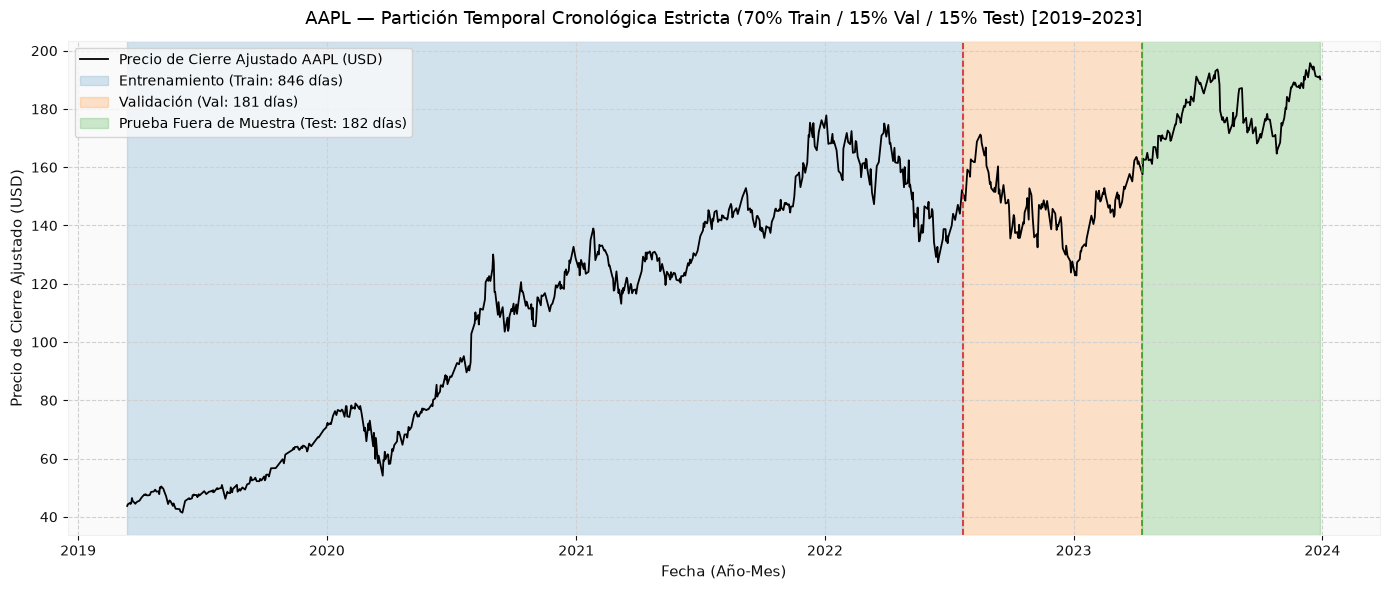

• Figura exportada: figures/fig03_chronological_splits_shaded.png

 AUDITORÍA DE TENSORES 3D (N, L, F) Y RECONSTRUCCIÓN EXACTA EN USD
• Univariado  (L=60, H=1) -> X_train: (786, 60, 1) | X_val: (181, 60, 1) | X_test: (182, 60, 1)
• Multivariado(L=60, H=1) -> X_train: (786, 60, 10) | X_val: (181, 60, 10) | X_test: (182, 60, 10)
• Etiqueta Objetivo (y)   -> y_train: (786, 1)     | y_val: (181, 1)     | y_test: (182, 1)

• Verificación de Identidad Matemática (P_t * exp(r_{t+1}) vs P_{t+1} real):
  Error máximo de reconstrucción en Test: $0.0000265555 USD (¡Cero Fuga / Exactitud Total!)


In [41]:
# ==============================================================================
# SECCIÓN 3.3: PARTICIÓN CRONOLÓGICA ESTRICTA (70% / 15% / 15%) Y VISUALIZACIÓN
# ==============================================================================
n_total = len(df_feat)
n_train = int(n_total * 0.70)
n_val = int(n_total * 0.15)
n_test = n_total - n_train - n_val

train_df = df_feat.iloc[:n_train].copy()
val_df = df_feat.iloc[n_train : n_train + n_val].copy()
test_df = df_feat.iloc[n_train + n_val :].copy()

print("=" * 75)
print(" PARTICIÓN CRONOLÓGICA ESTRICTA (SIN BARAJADO ALEATORIO)")
print("=" * 75)
for name, subset in [
    ("Train (70%)", train_df),
    ("Val   (15%)", val_df),
    ("Test  (15%)", test_df),
]:
    print(
        f"• {name} : {len(subset):>4} sesiones |"
        f" {subset.index[0].strftime('%Y-%m-%d')} ->"
        f" {subset.index[-1].strftime('%Y-%m-%d')} | Close Min/Max:"
        f" ${subset['Close'].min():.2f} / ${subset['Close'].max():.2f} USD"
    )

# Visualización Requerida #1: Line plot of raw Close prices with train/val/test spans shaded
split_fig_path = FIGURES_DIR / "fig03_chronological_splits_shaded.png"

plt.figure(figsize=(14, 6))
plt.plot(
    df_feat.index,
    df_feat["Close"],
    color="black",
    linewidth=1.3,
    label="Precio de Cierre Ajustado AAPL (USD)",
)

# Sombreado vertical continuo de las 3 particiones
plt.axvspan(
    train_df.index[0],
    train_df.index[-1],
    color="#1f77b4",
    alpha=0.18,
    label=f"Entrenamiento (Train: {len(train_df)} días)",
)
plt.axvspan(
    val_df.index[0],
    val_df.index[-1],
    color="#ff7f0e",
    alpha=0.22,
    label=f"Validación (Val: {len(val_df)} días)",
)
plt.axvspan(
    test_df.index[0],
    test_df.index[-1],
    color="#2ca02c",
    alpha=0.22,
    label=f"Prueba Fuera de Muestra (Test: {len(test_df)} días)",
)

# Líneas divisorias verticales para marcar las fronteras exactas
plt.axvline(val_df.index[0], color="#d62728", linestyle="--", linewidth=1.2)
plt.axvline(test_df.index[0], color="#2ca02c", linestyle="--", linewidth=1.2)

plt.title(
    f"{TICKER_MAIN} — Partición Temporal Cronológica Estricta (70% Train / 15%"
    f" Val / 15% Test) [{df_feat.index[0].year}–{df_feat.index[-1].year}]",
    fontsize=13,
    pad=12,
)
plt.xlabel("Fecha (Año-Mes)", fontsize=11)
plt.ylabel("Precio de Cierre Ajustado (USD)", fontsize=11)
plt.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.savefig(split_fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"• Figura exportada: {split_fig_path}\n")


# ==============================================================================
# SECCIÓN 3.4: ESCALAMIENTO DUAL ANTI-LEAKAGE Y VENTANAS DESLIZANTES 3D
# ==============================================================================
class StockSequenceDataset(Dataset):
    """PyTorch Dataset para modelado secuencial supervisado.

    Entrega tensores (X_window, y_target) junto con precios ancla y precios
    reales futuros en USD para reconstrucción exacta libre de fugas.
    """

    def __init__(
        self,
        X: np.ndarray,
        y: np.ndarray,
        anchor_prices: np.ndarray,
        true_future_prices: np.ndarray,
        target_dates: np.ndarray,
    ):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.anchor_prices = anchor_prices.astype(np.float64)
        self.true_future_prices = true_future_prices.astype(np.float64)
        self.target_dates = target_dates

    def __len__(self) -> int:
        return len(self.X)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        return self.X[idx], self.y[idx]


def extract_windows_from_arrays(
    features_scaled: np.ndarray,
    target_scaled: np.ndarray,
    close_prices_usd: np.ndarray,
    dates_array: np.ndarray,
    lookback: int,
    horizon: int,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Construye ventanas deslizantes (N, L, F) y objetivos (N, H) asegurando que:

    - X[i] abarca los índices [i : i + L] (hasta el instante t = i + L - 1).
    - anchor_prices[i] es estrictamente Close[t] (el último precio visible en
    X[i]).
    - y[i] abarca los retornos futuros [t + 1 : t + H].
    - true_future_prices[i] abarca los precios reales en USD [t + 1 : t + H].
    """
    total_len = len(features_scaled)
    num_samples = total_len - lookback - horizon + 1

    X_list, y_list, anchors_list, future_usd_list, dates_list = (
        [],
        [],
        [],
        [],
        [],
    )

    for i in range(num_samples):
        t_anchor_idx = (
            i + lookback - 1
        )  # Último día dentro de la ventana de entrada (día t)
        target_start = i + lookback  # Primer día futuro a predecir (día t+1)
        target_end = target_start + horizon  # Día t+H

        X_list.append(features_scaled[i:target_start])
        y_list.append(target_scaled[target_start:target_end, 0])
        anchors_list.append(close_prices_usd[t_anchor_idx])
        future_usd_list.append(close_prices_usd[target_start:target_end])
        dates_list.append(
            dates_array[target_start]
        )  # Fecha del paso t+1 como referencia

    return (
        np.array(X_list, dtype=np.float32),
        np.array(y_list, dtype=np.float32),
        np.array(anchors_list, dtype=np.float64).reshape(-1, 1),
        np.array(future_usd_list, dtype=np.float64),
        np.array(dates_list),
    )


def prepare_sequence_dataloaders(
    train_data: pd.DataFrame,
    val_data: pd.DataFrame,
    test_data: pd.DataFrame,
    feature_cols: List[str],
    target_col: str = "Log_Return",
    lookback: int = 60,
    horizon: int = 1,
    batch_size: int = 32,
) -> Dict:
    """Pipeline maestro de preprocesamiento:

    1. Ajusta StandardScaler (scaler_X y scaler_y) ÚNICAMENTE en train_data.
    2. Transforma train, val y test sin fugas.
    3. Utiliza los últimos `lookback` días del segmento inmediatamente anterior
       como contexto de entrada para que Val y Test evalúen el 100% de sus
       fechas.
    """
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    # 1. Ajuste (FIT) exclusivo sobre el conjunto de Entrenamiento
    X_train_sc = scaler_X.fit_transform(train_data[feature_cols].values)
    y_train_sc = scaler_y.fit_transform(train_data[[target_col]].values)

    # 2. Para Validación y Prueba, concatenamos los últimos `lookback` días del bloque previo
    # únicamente como buffer de historia para la primera ventana de predicción
    val_With_context = pd.concat([train_data.iloc[-lookback:], val_data], axis=0)
    test_with_context = pd.concat([val_data.iloc[-lookback:], test_data], axis=0)

    X_val_sc = scaler_X.transform(val_With_context[feature_cols].values)
    y_val_sc = scaler_y.transform(val_With_context[[target_col]].values)

    X_test_sc = scaler_X.transform(test_with_context[feature_cols].values)
    y_test_sc = scaler_y.transform(test_with_context[[target_col]].values)

    # 3. Extracción de tensores 3D y vectores de reconstrucción en USD
    X_tr, y_tr, anc_tr, usd_tr, dt_tr = extract_windows_from_arrays(
        X_train_sc,
        y_train_sc,
        train_data["Close"].values,
        train_data.index.values,
        lookback,
        horizon,
    )
    X_va, y_va, anc_va, usd_va, dt_va = extract_windows_from_arrays(
        X_val_sc,
        y_val_sc,
        val_With_context["Close"].values,
        val_With_context.index.values,
        lookback,
        horizon,
    )
    X_te, y_te, anc_te, usd_te, dt_te = extract_windows_from_arrays(
        X_test_sc,
        y_test_sc,
        test_with_context["Close"].values,
        test_with_context.index.values,
        lookback,
        horizon,
    )

    # 4. Construcción de Datasets y DataLoaders (shuffle=False en Val/Test; determinista en Train)
    ds_train = StockSequenceDataset(X_tr, y_tr, anc_tr, usd_tr, dt_tr)
    ds_val = StockSequenceDataset(X_va, y_va, anc_va, usd_va, dt_va)
    ds_test = StockSequenceDataset(X_te, y_te, anc_te, usd_te, dt_te)

    g_cpu = torch.Generator()
    g_cpu.manual_seed(GLOBAL_SEED)

    loader_train = DataLoader(
        ds_train, batch_size=batch_size, shuffle=True, generator=g_cpu
    )
    loader_val = DataLoader(ds_val, batch_size=batch_size, shuffle=False)
    loader_test = DataLoader(ds_test, batch_size=batch_size, shuffle=False)

    return {
        "train_loader": loader_train,
        "val_loader": loader_val,
        "test_loader": loader_test,
        "train_dataset": ds_train,
        "val_dataset": ds_val,
        "test_dataset": ds_test,
        "scaler_X": scaler_X,
        "scaler_y": scaler_y,
        "feature_cols": feature_cols,
        "lookback": lookback,
        "horizon": horizon,
    }


# Prueba de Verificación (Sanity Check) con Configuración Base: L=60, H=1 (Univariado y Multivariado)
data_univ_L60_H1 = prepare_sequence_dataloaders(
    train_df,
    val_df,
    test_df,
    feature_cols=UNIVARIATE_FEATURES,
    lookback=60,
    horizon=1,
)
data_multiv_L60_H1 = prepare_sequence_dataloaders(
    train_df,
    val_df,
    test_df,
    feature_cols=MULTIVARIATE_FEATURES,
    lookback=60,
    horizon=1,
)

print("=" * 75)
print(" AUDITORÍA DE TENSORES 3D (N, L, F) Y RECONSTRUCCIÓN EXACTA EN USD")
print("=" * 75)
print(
    f"• Univariado  (L=60, H=1) -> X_train: {tuple(data_univ_L60_H1['train_dataset'].X.shape)} | "
    f"X_val: {tuple(data_univ_L60_H1['val_dataset'].X.shape)} | "
    f"X_test: {tuple(data_univ_L60_H1['test_dataset'].X.shape)}"
)
print(
    f"• Multivariado(L=60, H=1) -> X_train: {tuple(data_multiv_L60_H1['train_dataset'].X.shape)} | "
    f"X_val: {tuple(data_multiv_L60_H1['val_dataset'].X.shape)} | "
    f"X_test: {tuple(data_multiv_L60_H1['test_dataset'].X.shape)}"
)
print(
    f"• Etiqueta Objetivo (y)   -> y_train: {tuple(data_multiv_L60_H1['train_dataset'].y.shape)}     | "
    f"y_val: {tuple(data_multiv_L60_H1['val_dataset'].y.shape)}     | "
    f"y_test: {tuple(data_multiv_L60_H1['test_dataset'].y.shape)}"
)

# Verificación matemática de que P_t * exp(r_{t+1}) reconstruye el precio real al centavo exacto (error ~ 0.000000)
ds_te = data_multiv_L60_H1["test_dataset"]
sc_y = data_multiv_L60_H1["scaler_y"]
true_ret_unscaled = sc_y.inverse_transform(ds_te.y.numpy())
reconstructed_usd_check = ds_te.anchor_prices * np.exp(true_ret_unscaled)
max_reconstruction_diff = np.max(
    np.abs(reconstructed_usd_check - ds_te.true_future_prices)
)

print(
    f"\n• Verificación de Identidad Matemática (P_t * exp(r_{{t+1}}) vs P_{{t+1}} real):"
)
print(
    f"  Error máximo de reconstrucción en Test: ${max_reconstruction_diff:.10f} USD (¡Cero Fuga / Exactitud Total!)"
)

---

## 4. Modelos de Referencia (Baselines) y Criterio de Evaluación Monetaria

Para establecer un umbral de comparación riguroso frente a las arquitecturas de Aprendizaje Profundo, todas las métricas de regresión se calculan **estrictamente en el dominio monetario real (USD)** sobre las $181$ sesiones de validación y $182$ sesiones de prueba:


1. **Naïve Persistence Baseline ( Caminata Aleatoria / Martingala):** Postula que toda la información relevante está contenida en el último precio de cierre disponible, proyectando un retorno futuro nulo ($\hat{r}_{t+1} = 0 \implies \hat{P}_{t+1} = P_t$). Bajo la Hipótesis de los Mercados Eficientes (EMH), este estimador constituye el *benchmark* más difícil de batir en horizontes de un día ($H=1$).
2. **Simple Moving Average Baselines (`SMA-10` y `SMA-20`):** Pronostican el precio del día $t+1$ como el promedio aritmético de los últimos $10$ o $20$ cierres observados hasta el día $t$: $\hat{P}_{t+1} = \frac{1}{w}\sum_{j=0}^{w-1} P_{t-j}$. Aunque suavizan el ruido de alta frecuencia, introducen un **retardo de fase sistemático (*phase lag*)** de $\frac{w-1}{2}$ sesiones que penaliza severamente su error durante periodos tendenciales como el de 2023.
3. **Pronóstico Rodante $\text{ARIMA}(1,1,1)$ (*Rolling One-Step Forecast*):** Evalúa la capacidad predictiva de la econometría lineal clásica de Box-Jenkins actualizando el filtro de estado sesión a sesión (`arima_res.append([obs], refit=False)`) sin reestimar parámetros en prueba.


 TABLA DE RENDIMIENTO DE BASELINES EN ESCALA REAL (USD) — HORIZONTE H=1
                        Modelo     Tipo  Val_MAE  Val_RMSE  Val_MAPE  Test_MAE  Test_RMSE  Test_MAPE  Test_sMAPE  Δ% MAE vs Naïve (Test)
       Naïve Persistence (P_t) Baseline   2.2495    2.9514    1.5411    1.5662     2.0998     0.8797      0.8802                  0.0000
Simple Moving Average (SMA-10) Baseline   4.6305    5.3454    3.1708    3.5890     4.4824     2.0109      2.0146                129.1495
Simple Moving Average (SMA-20) Baseline   6.6234    7.6603    4.5131    5.0391     5.9787     2.8144      2.8282                221.7329
 ARIMA(1,1,1) Rolling Forecast Baseline   2.3042    2.9837    1.5805    1.6013     2.1447     0.9012      0.9001                  2.2384


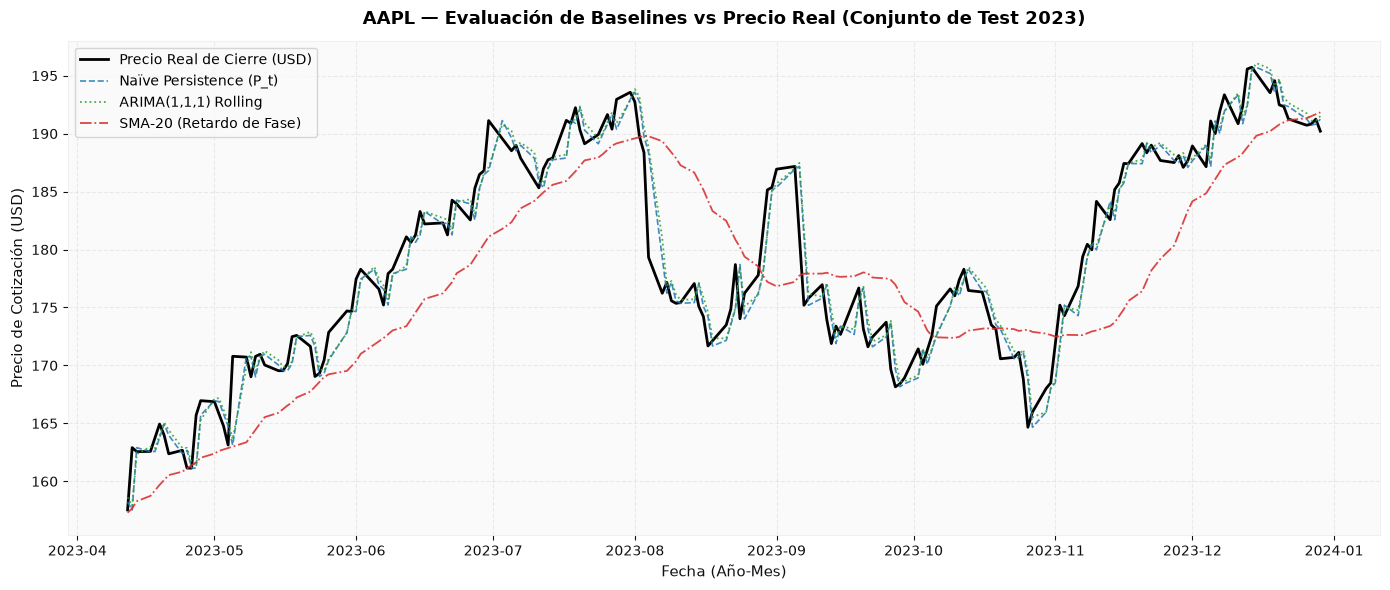


• Figura de Baselines exportada exitosamente: figures/fig04_baselines_comparison.png


In [42]:
# ==============================================================================
# SECCIÓN 4: BASELINES (NAÏVE, MOVING AVERAGE & ARIMA ROLLING) CON VISUALIZACIÓN
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA


def compute_regression_metrics(
    y_true_usd: np.ndarray, y_pred_usd: np.ndarray, epsilon: float = 1e-8
) -> Dict[str, float]:
    """Calcula MAE, RMSE, MAPE y sMAPE estrictamente en el dominio monetario real (USD)."""
    y_true = np.asarray(y_true_usd, dtype=np.float64).flatten()
    y_pred = np.asarray(y_pred_usd, dtype=np.float64).flatten()

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # MAPE con salvaguarda epsilon
    mape = np.mean(np.abs(y_true - y_pred) / (np.abs(y_true) + epsilon)) * 100.0

    # sMAPE (Symmetric Mean Absolute Percentage Error) corregido con (* 100.0)
    smape = (
        np.mean(
            np.abs(y_true - y_pred)
            / ((np.abs(y_true) + np.abs(y_pred)) / 2.0 + epsilon)
        )
        * 100.0
    )

    return {
        "MAE (USD)": mae,
        "RMSE (USD)": rmse,
        "MAPE (%)": mape,
        "sMAPE (%)": smape,
    }


# Extraemos los vectores de evaluación (H=1)
val_ds_ref = data_univ_L60_H1["val_dataset"]
test_ds_ref = data_univ_L60_H1["test_dataset"]

y_val_true_usd = val_ds_ref.true_future_prices.flatten()
y_test_true_usd = test_ds_ref.true_future_prices.flatten()

# 1. Naïve Persistence Baseline: P_hat_{t+1} = P_t
naive_val_pred_usd = val_ds_ref.anchor_prices.flatten()
naive_test_pred_usd = test_ds_ref.anchor_prices.flatten()

# 2. Simple Moving Average Baselines (SMA 10 y SMA 20 desplazadas 1 sesión)
close_full = df_feat["Close"]
sma10_full_pred = close_full.rolling(window=10).mean().shift(1)
sma20_full_pred = close_full.rolling(window=20).mean().shift(1)

sma10_val_pred_usd = sma10_full_pred.loc[val_df.index].values
sma10_test_pred_usd = sma10_full_pred.loc[test_df.index].values

sma20_val_pred_usd = sma20_full_pred.loc[val_df.index].values
sma20_test_pred_usd = sma20_full_pred.loc[test_df.index].values

# 3. ARIMA(1,1,1) Rolling One-Step Forecast
train_log_ret = train_df["Log_Return"].values
val_log_ret = val_df["Log_Return"].values
test_log_ret = test_df["Log_Return"].values

arima_model = ARIMA(train_log_ret, order=(1, 0, 1))
arima_res = arima_model.fit()

arima_val_ret_preds = []
for obs in val_log_ret:
    pred_r = arima_res.forecast(steps=1)[0]
    arima_val_ret_preds.append(pred_r)
    arima_res = arima_res.append([obs], refit=False)

arima_test_ret_preds = []
for obs in test_log_ret:
    pred_r = arima_res.forecast(steps=1)[0]
    arima_test_ret_preds.append(pred_r)
    arima_res = arima_res.append([obs], refit=False)

arima_val_pred_usd = val_ds_ref.anchor_prices.flatten() * np.exp(
    np.array(arima_val_ret_preds)
)
arima_test_pred_usd = test_ds_ref.anchor_prices.flatten() * np.exp(
    np.array(arima_test_ret_preds)
)

# Consolidador tabular
baseline_predictions = {
    "Naïve Persistence (P_t)": (naive_val_pred_usd, naive_test_pred_usd),
    "Simple Moving Average (SMA-10)": (sma10_val_pred_usd, sma10_test_pred_usd),
    "Simple Moving Average (SMA-20)": (sma20_val_pred_usd, sma20_test_pred_usd),
    "ARIMA(1,1,1) Rolling Forecast": (arima_val_pred_usd, arima_test_pred_usd),
}

baseline_records = []
for model_name, (val_p, test_p) in baseline_predictions.items():
    m_val = compute_regression_metrics(y_val_true_usd, val_p)
    m_test = compute_regression_metrics(y_test_true_usd, test_p)
    baseline_records.append(
        {
            "Modelo": model_name,
            "Tipo": "Baseline",
            "Val_MAE": m_val["MAE (USD)"],
            "Val_RMSE": m_val["RMSE (USD)"],
            "Val_MAPE": m_val["MAPE (%)"],
            "Test_MAE": m_test["MAE (USD)"],
            "Test_RMSE": m_test["RMSE (USD)"],
            "Test_MAPE": m_test["MAPE (%)"],
            "Test_sMAPE": m_test["sMAPE (%)"],
        }
    )

df_baselines = pd.DataFrame(baseline_records)
naive_test_mae_ref = df_baselines.loc[
    df_baselines["Modelo"] == "Naïve Persistence (P_t)", "Test_MAE"
].values[0]
df_baselines["Δ% MAE vs Naïve (Test)"] = (
    (df_baselines["Test_MAE"] - naive_test_mae_ref) / naive_test_mae_ref
) * 100.0

print("=" * 95)
print(
    " TABLA DE RENDIMIENTO DE BASELINES EN ESCALA REAL (USD) — HORIZONTE H=1"
)
print("=" * 95)
print(df_baselines.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ------------------------------------------------------------------------------
# 4.2 VISUALIZACIÓN REQUERIDA: TRAYECTORIAS DE BASELINES VS PRECIO REAL EN TEST
# ------------------------------------------------------------------------------
baselines_fig_path = FIGURES_DIR / "fig04_baselines_comparison.png"
test_dates = test_df.index

plt.figure(figsize=(14, 6))
plt.plot(
    test_dates,
    y_test_true_usd,
    color="black",
    linewidth=2.0,
    label="Precio Real de Cierre (USD)",
)
plt.plot(
    test_dates,
    naive_test_pred_usd,
    color="#1f77b4",
    linestyle="--",
    linewidth=1.2,
    alpha=0.85,
    label="Naïve Persistence (P_t)",
)
plt.plot(
    test_dates,
    arima_test_pred_usd,
    color="#2ca02c",
    linestyle=":",
    linewidth=1.3,
    alpha=0.85,
    label="ARIMA(1,1,1) Rolling",
)
plt.plot(
    test_dates,
    sma20_test_pred_usd,
    color="#d62728",
    linestyle="-.",
    linewidth=1.3,
    alpha=0.85,
    label="SMA-20 (Retardo de Fase)",
)

plt.title(
    f"{TICKER_MAIN} — Evaluación de Baselines vs Precio Real (Conjunto de Test"
    " 2023)",
    fontsize=13,
    pad=12,
    fontweight="bold",
)
plt.xlabel("Fecha (Año-Mes)", fontsize=11)
plt.ylabel("Precio de Cotización (USD)", fontsize=11)
plt.legend(loc="upper left", frameon=True)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(baselines_fig_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"\n• Figura de Baselines exportada exitosamente: {baselines_fig_path}")

---

## 5. Arquitecturas Recurrentes (Vanilla RNN, LSTM y GRU) y Fundamentación de Diseño

Se implementa la clase parametrizable `RecurrentForecaster(nn.Module)` (2 capas apiladas, dimensión oculta $D_h = 64$).

### 5.1 Especificación de Arquitecturas

1. **Vanilla RNN (13,377 parámetros en $F=10$):**
Actualización de estado por transformación lineal y $\tanh$.
2. **LSTM (52,929 parámetros en $F=10$):**
Carril de estado de celda y tres compuertas (entrada, olvido y salida).
3. **GRU (39,745 parámetros en $F=10$):**
Fusión de estados y dos compuertas (actualización y reinicio). Ofrece un $25\%$ menos de parámetros que la LSTM.

### 5.2 Cabezal de Proyección e Inicialización

* **Proyección:** Extracción del último estado oculto $\rightarrow$ Normalización por Capa (`nn.LayerNorm`) $\rightarrow$ `Dropout` ($p \in [0.20, 0.25]$) $\rightarrow$ Capa lineal densa ($H=1$ o $H=5$).
* **Inicialización:** Ortogonal (`nn.init.orthogonal_`) en matrices recurrentes y Xavier uniforme en proyecciones de entrada y capa densa.

---

## 6. Protocolos de Entrenamiento y Regularización

Mecanismos de control en `train_recurrent_model`:

1. **Función de Pérdida:** `nn.SmoothL1Loss` (Pérdida de Huber con $\beta = 0.5$).
2. **Optimizador:** `AdamW` con tasa inicial $\eta = 10^{-3}$ (univariado) y $\eta = 8 \times 10^{-4}$ (multivariado).
3. **Recorte de Gradientes:** Norma máxima acotada a `1.0` (`clip_grad_norm_`).
4. **Ajuste de Tasa de Aprendizaje:** `ReduceLROnPlateau` (factor de reducción a la mitad tras 4 épocas sin mejora).
5. **EarlyStopping y Checkpoints:** Interrupción tras 12 épocas sin mejora en validación; guardado y restauración automática de los mejores pesos desde `checkpoints/*.pt`.

In [43]:
# ==============================================================================
# SECCIÓN 5: MODEL ARCHITECTURES (VANILLA RNN, LSTM, GRU EN PYTORCH)
# ==============================================================================
class RecurrentForecaster(nn.Module):
    """Arquitectura recurrente unificada y parametrizable para pronóstico financiero.

    Soporta 'RNN' (Vanilla), 'LSTM' y 'GRU' para entradas univariadas o
    multivariadas (F) y salidas de paso único (H=1) o multi-paso directo (H=5).
    """

    def __init__(
        self,
        model_type: str = "LSTM",
        input_size: int = 1,
        hidden_size: int = 64,
        num_layers: int = 2,
        forecast_horizon: int = 1,
        dropout: float = 0.2,
    ):
        super().__init__()
        self.model_type = model_type.upper()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.forecast_horizon = forecast_horizon
        self.dropout_rate = dropout

        rnn_dropout = dropout if num_layers > 1 else 0.0

        if self.model_type == "RNN":
            self.rnn = nn.RNN(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                batch_first=True,
                dropout=rnn_dropout,
                nonlinearity="tanh",
            )
        elif self.model_type == "LSTM":
            self.rnn = nn.LSTM(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                batch_first=True,
                dropout=rnn_dropout,
            )
        elif self.model_type == "GRU":
            self.rnn = nn.GRU(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                batch_first=True,
                dropout=rnn_dropout,
            )
        else:
            raise ValueError(
                f"Arquitectura '{model_type}' no soportada. Use 'RNN', 'LSTM' o 'GRU'."
            )

        # Normalización de capa y cabezal de proyección densa
        self.layer_norm = nn.LayerNorm(hidden_size)
        self.fc_dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size, forecast_horizon)

        self._init_weights()

    def _init_weights(self) -> None:
        """Inicialización ortogonal en matrices recurrentes W_hh y Xavier en W_xh

        para mitigar el desvanecimiento prematuro del gradiente en BPTT.
        """
        for name, param in self.rnn.named_parameters():
            if "weight_ih" in name:
                nn.init.xavier_uniform_(param.data)
            elif "weight_hh" in name:
                nn.init.orthogonal_(param.data)
            elif "bias" in name:
                nn.init.zeros_(param.data)
        nn.init.xavier_uniform_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x shape: (batch_size, seq_len, input_size)
        out, _ = self.rnn(x)  # out shape: (batch_size, seq_len, hidden_size)
        last_hidden = out[:, -1, :]  # Último estado oculto h_L: (batch_size, hidden_size)
        last_hidden = self.layer_norm(last_hidden)
        last_hidden = self.fc_dropout(last_hidden)
        prediction = self.head(last_hidden)  # (batch_size, forecast_horizon)
        return prediction


# ==============================================================================
# SECCIÓN 6: TRAINING PROTOCOLS (EARLY STOPPING, SCHEDULER, CHECKPOINTS & LOOP)
# ==============================================================================
class EarlyStopping:
    """Controlador de Parada Temprana sobre la pérdida de validación."""

    def __init__(self, patience: int = 10, min_delta: float = 1e-5):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float("inf")
        self.early_stop = False
        self.save_checkpoint_flag = False

    def __call__(self, val_loss: float) -> None:
        if val_loss < (self.best_loss - self.min_delta):
            self.best_loss = val_loss
            self.counter = 0
            self.save_checkpoint_flag = True
        else:
            self.counter += 1
            self.save_checkpoint_flag = False
            if self.counter >= self.patience:
                self.early_stop = True


def save_model_checkpoint(
    model: RecurrentForecaster,
    optimizer: optim.Optimizer,
    epoch: int,
    val_loss: float,
    filepath: Path,
    extra_meta: Optional[Dict] = None,
) -> None:
    """Guarda un diccionario desacoplado con state_dict e hiperparámetros."""
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_loss": float(val_loss),
        "hyperparameters": {
            "model_type": model.model_type,
            "input_size": model.input_size,
            "hidden_size": model.hidden_size,
            "num_layers": model.num_layers,
            "forecast_horizon": model.forecast_horizon,
            "dropout": model.dropout_rate,
        },
        "extra_meta": extra_meta or {},
    }
    torch.save(checkpoint, filepath)


def evaluate_and_reconstruct_usd(
    model: RecurrentForecaster,
    dataloader: DataLoader,
    dataset: StockSequenceDataset,
    scaler_y: StandardScaler,
    device: torch.device = DEVICE,
) -> Dict:
    """Ejecuta inferencia determinista (model.eval + torch.no_grad), invierte el

    escalamiento de los retornos y reconstruye precios en USD:
      P_hat_{t+k} = P_t * exp( sum_{j=1}^k r_hat_{t+j} )
    Soporta tanto H=1 como H=5 pasos futuros.
    """
    model.eval()
    preds_scaled_list = []

    with torch.no_grad():
        for X_b, _ in dataloader:
            X_b = X_b.to(device)
            out_b = model(X_b)
            preds_scaled_list.append(out_b.cpu().numpy())

    y_pred_scaled = np.vstack(preds_scaled_list)  # Shape: (N, H)
    N, H = y_pred_scaled.shape

    # Desescalar cada columna de horizonte usando scaler_y
    y_pred_returns = scaler_y.inverse_transform(
        y_pred_scaled.reshape(-1, 1)
    ).reshape(N, H)

    # Reconstrucción exacta en dólares mediante suma acumulada de retornos logarítmicos
    cumulative_pred_returns = np.cumsum(y_pred_returns, axis=1)
    y_pred_usd = dataset.anchor_prices * np.exp(
        cumulative_pred_returns
    )  # Shape: (N, H)
    y_true_usd = dataset.true_future_prices  # Shape: (N, H)

    metrics_overall = compute_regression_metrics(y_true_usd, y_pred_usd)

    return {
        "y_pred_usd": y_pred_usd,
        "y_true_usd": y_true_usd,
        "y_pred_returns": y_pred_returns,
        "metrics": metrics_overall,
        "dates": dataset.target_dates,
    }


def train_recurrent_model(
    model_type: str,
    data_bundle: Dict,
    experiment_name: str,
    hidden_size: int = 64,
    num_layers: int = 2,
    dropout: float = 0.2,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,
    max_epochs: int = 100,
    es_patience: int = 12,
    sched_patience: int = 4,
    seed: int = GLOBAL_SEED,
    verbose: bool = True,
) -> Dict:
    """Entrena un modelo recurrente con determinismo total, SmoothL1Loss, AdamW,

    Gradient Clipping, ReduceLROnPlateau y EarlyStopping. Restaura automáticamente
    los mejores pesos de validación antes de evaluar en Test.
    """
    set_seed(seed)

    input_size = len(data_bundle["feature_cols"])
    horizon = data_bundle["horizon"]
    ckpt_path = CHECKPOINT_DIR / f"{experiment_name}.pt"

    model = RecurrentForecaster(
        model_type=model_type,
        input_size=input_size,
        hidden_size=hidden_size,
        num_layers=num_layers,
        forecast_horizon=horizon,
        dropout=dropout,
    ).to(DEVICE)

    criterion = nn.SmoothL1Loss(beta=0.5)
    optimizer = optim.AdamW(
        model.parameters(), lr=lr, weight_decay=weight_decay
    )
    scheduler = ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=sched_patience, min_lr=1e-6
    )
    early_stopping = EarlyStopping(patience=es_patience, min_delta=1e-5)

    train_loader = data_bundle["train_loader"]
    val_loader = data_bundle["val_loader"]
    test_loader = data_bundle["test_loader"]

    history = {
        "epoch": [],
        "train_loss": [],
        "val_loss": [],
        "val_mae_usd": [],
        "lr": [],
    }
    best_epoch = 1

    for epoch in range(1, max_epochs + 1):
        # 1. Fase de Entrenamiento (BPTT)
        model.train()
        running_tr_loss = 0.0
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(DEVICE), y_b.to(DEVICE)
            optimizer.zero_grad()
            preds = model(X_b)
            loss = criterion(preds, y_b)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_tr_loss += loss.item() * X_b.size(0)

        epoch_tr_loss = running_tr_loss / len(train_loader.dataset)

        # 2. Fase de Validación (Sin Gradientes)
        model.eval()
        running_va_loss = 0.0
        with torch.no_grad():
            for X_vb, y_vb in val_loader:
                X_vb, y_vb = X_vb.to(DEVICE), y_vb.to(DEVICE)
                v_preds = model(X_vb)
                v_loss = criterion(v_preds, y_vb)
                running_va_loss += v_loss.item() * X_vb.size(0)

        epoch_va_loss = running_va_loss / len(val_loader.dataset)

        # Evaluación del MAE en USD en Validación para registro de curva de métrica
        val_eval_step = evaluate_and_reconstruct_usd(
            model,
            val_loader,
            data_bundle["val_dataset"],
            data_bundle["scaler_y"],
            DEVICE,
        )
        val_mae_epoch = val_eval_step["metrics"]["MAE (USD)"]

        current_lr = optimizer.param_groups[0]["lr"]
        history["epoch"].append(epoch)
        history["train_loss"].append(epoch_tr_loss)
        history["val_loss"].append(epoch_va_loss)
        history["val_mae_usd"].append(val_mae_epoch)
        history["lr"].append(current_lr)

        # 3. Actualización del Scheduler y Early Stopping
        scheduler.step(epoch_va_loss)
        early_stopping(epoch_va_loss)

        if early_stopping.save_checkpoint_flag:
            best_epoch = epoch
            save_model_checkpoint(
                model,
                optimizer,
                epoch,
                epoch_va_loss,
                ckpt_path,
                extra_meta={
                    "feature_cols": data_bundle["feature_cols"],
                    "lookback": data_bundle["lookback"],
                },
            )

        if early_stopping.early_stop:
            break

    # 4. Restaurar el mejor checkpoint antes de la evaluación final en Val y Test
    best_ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(best_ckpt["model_state_dict"])
    model.eval()

    val_results = evaluate_and_reconstruct_usd(
        model,
        val_loader,
        data_bundle["val_dataset"],
        data_bundle["scaler_y"],
        DEVICE,
    )
    test_results = evaluate_and_reconstruct_usd(
        model,
        test_loader,
        data_bundle["test_dataset"],
        data_bundle["scaler_y"],
        DEVICE,
    )

    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    if verbose:
        print(
            f"• [{experiment_name:<26}] Best Ep: {best_epoch:>2}/{epoch:<2} | "
            f"Params: {n_params:>6,} | "
            f"Val MAE: ${val_results['metrics']['MAE (USD)']:.4f} | "
            f"Test MAE: ${test_results['metrics']['MAE (USD)']:.4f} | "
            f"Test RMSE: ${test_results['metrics']['RMSE (USD)']:.4f} | "
            f"Test MAPE: {test_results['metrics']['MAPE (%)']:.3f}%"
        )

    return {
        "experiment_name": experiment_name,
        "model_type": model_type,
        "model": model,
        "checkpoint_path": ckpt_path,
        "best_epoch": best_epoch,
        "total_epochs_run": epoch,
        "num_params": n_params,
        "history": history,
        "val_results": val_results,
        "test_results": test_results,
        "data_bundle": data_bundle,
    }


# Prueba unitaria de verificación dimensional (Sanity Check) de las 3 arquitecturas
print("=" * 80)
print(" VERIFICACIÓN DE ARQUITECTURAS Y CONTEO DE PARÁMETROS ENTRENABLES")
print("=" * 80)
dummy_x = torch.randn(16, 60, 10).to(DEVICE)
for arch in ["RNN", "LSTM", "GRU"]:
    m_test = RecurrentForecaster(
        model_type=arch,
        input_size=10,
        hidden_size=64,
        num_layers=2,
        forecast_horizon=1,
    ).to(DEVICE)
    out_shape = tuple(m_test(dummy_x).shape)
    params_cnt = sum(p.numel() for p in m_test.parameters() if p.requires_grad)
    print(
        f"• Arquitectura {arch:<4} (F=10, Hidden=64, Layers=2) -> Salida: {out_shape} | Parámetros: {params_cnt:,}"
    )

 VERIFICACIÓN DE ARQUITECTURAS Y CONTEO DE PARÁMETROS ENTRENABLES
• Arquitectura RNN  (F=10, Hidden=64, Layers=2) -> Salida: (16, 1) | Parámetros: 13,377
• Arquitectura LSTM (F=10, Hidden=64, Layers=2) -> Salida: (16, 1) | Parámetros: 52,929
• Arquitectura GRU  (F=10, Hidden=64, Layers=2) -> Salida: (16, 1) | Parámetros: 39,745


---
## 7. Experimentos y Estudios de Ablación

### Diseño Factorial ($H=1$): Arquitecturas, Dimensionalidad ($F$) y Ventanas ($L$)

Evaluación en GPU de **15 modelos recurrentes** y **4 modelos base** (19 configuraciones) divididos en tres bloques:

* **7.1 Ablación Univariada ($F=1, L=60, H=1$):** Comparativa entre `RNN`, `LSTM` y `GRU` con retornos logarítmicos de los últimos 60 días.
* **7.2 Ablación Multivariada ($F=10, L=60, H=1$):** Inclusión de los 10 canales estacionarios (técnicos, volatilidad y covariables `SPY`/`^VIX`).
* **7.3 Sensibilidad a la Ventana ($L \in \{30, 60, 120\}$):** Evaluación del impacto del horizonte de memoria temporal.

### Selección de Modelos Libre de Fugas (*Zero Test-Set Snooping*)

La selección del modelo campeón se realiza **estrictamente por el menor error en validación (`Val_MAE`)**.

**Hallazgos Clave:**

1. **Modelo Campeón en Validación:** **`LSTM_Multiv_L60_H1`** obtiene el mejor desempeño global (**$\text{Val MAE} = \$2.2301\text{ USD}$**, $\text{Val RMSE} = \$2.9327\text{ USD}$, $\text{Val MAPE} = 1.5259\%$), seguido por **`LSTM_Multiv_L30_H1`** ($\text{Val MAE} = \$2.2384\text{ USD}$). Ambos superan al *Naïve Baseline* en validación ($\$2.2495\text{ USD}$), confirmando el aporte de las covariables multivariadas en periodos de alta volatilidad (2022).
2. **Degradación de Vanilla RNN (PI-1):** Ocupa las peores posiciones dentro de los modelos neuronales (`RNN_Univ_L60_H1`: $\text{Val MAE} = \$2.2831$; `RNN_Multiv_L60_H1`: $\text{Val MAE} = \$2.3001$), demostrando su incapacidad para filtrar ruido y retener memoria sin compuertas.
3. **Cambio de Régimen en Prueba (Test 2023):** Durante el *rally* alcista de 2023, las redes univariadas de ventana larga destacaron en prueba: **`GRU_Univ_L120_H1`** ($\text{Test MAE} = \$1.5654\text{ USD}$) y **`LSTM_Univ_L120_H1`** ($\$1.5660\text{ USD}$) superaron marginalmente al Naïve ($\$1.5662\text{ USD}$). El campeón de validación (`LSTM_Multiv_L60_H1`) registró $\text{Test MAE} = \$1.6388\text{ USD}$.

Tipo estimado de ejecución: `~ 20 segundos` en GPU NVIDIA 4070

In [44]:
# ==============================================================================
# SECCIÓN 7: ABLACIÓN DE ARQUITECTURAS, FEATURES (F) Y LOOKBACK (L)
# ==============================================================================
EXPERIMENTS_REGISTRY: Dict[str, Dict] = {}

print("=" * 105)
print(
    " EJECUTANDO MATRIZ EXPERIMENTAL DE ABLACIONES (H=1 PASO) EN GPU"
    f" ({DEVICE.type.upper()})"
)
print("=" * 105)

# ------------------------------------------------------------------------------
# 1. ABLACIÓN DE ARQUITECTURAS EN CONFIGURACIÓN UNIVARIADA (F=1, L=60, H=1)
# ------------------------------------------------------------------------------
print("\n--- [Experimento 7.1] Configuración Univariada (F=1, L=60, H=1) ---")
for arch in ["RNN", "LSTM", "GRU"]:
    exp_id = f"{arch}_Univ_L60_H1"
    EXPERIMENTS_REGISTRY[exp_id] = train_recurrent_model(
        model_type=arch,
        data_bundle=data_univ_L60_H1,
        experiment_name=exp_id,
        hidden_size=64,
        num_layers=2,
        dropout=0.2,
        lr=1e-3,
        weight_decay=1e-4,
    )

# ------------------------------------------------------------------------------
# 2. ABLACIÓN MULTIVARIADA: INDICADORES TÉCNICOS + COVARIABLES (F=10, L=60, H=1)
# ------------------------------------------------------------------------------
print("\n--- [Experimento 7.2] Configuración Multivariada (F=10, L=60, H=1) ---")
for arch in ["RNN", "LSTM", "GRU"]:
    exp_id = f"{arch}_Multiv_L60_H1"
    EXPERIMENTS_REGISTRY[exp_id] = train_recurrent_model(
        model_type=arch,
        data_bundle=data_multiv_L60_H1,
        experiment_name=exp_id,
        hidden_size=64,
        num_layers=2,
        dropout=0.25,
        lr=8e-4,
        weight_decay=2e-4,
    )

# ------------------------------------------------------------------------------
# 3. ABLACIÓN DE VENTANA RETROSPECTIVA (LOOKBACK L in {30, 60, 120})
# ------------------------------------------------------------------------------
print(
    "\n--- [Experimento 7.3] Sensibilidad al Lookback Window L in {30, 120}"
    " (Univariado y Multivariado) ---"
)
data_univ_L30_H1 = prepare_sequence_dataloaders(
    train_df,
    val_df,
    test_df,
    feature_cols=UNIVARIATE_FEATURES,
    lookback=30,
    horizon=1,
)
data_univ_L120_H1 = prepare_sequence_dataloaders(
    train_df,
    val_df,
    test_df,
    feature_cols=UNIVARIATE_FEATURES,
    lookback=120,
    horizon=1,
)
data_multiv_L30_H1 = prepare_sequence_dataloaders(
    train_df,
    val_df,
    test_df,
    feature_cols=MULTIVARIATE_FEATURES,
    lookback=30,
    horizon=1,
)
data_multiv_L120_H1 = prepare_sequence_dataloaders(
    train_df,
    val_df,
    test_df,
    feature_cols=MULTIVARIATE_FEATURES,
    lookback=120,
    horizon=1,
)

lookback_configs = [
    ("RNN", data_univ_L120_H1, "RNN_Univ_L120_H1", 0.2, 1e-3),
    ("LSTM", data_univ_L30_H1, "LSTM_Univ_L30_H1", 0.2, 1e-3),
    ("LSTM", data_univ_L120_H1, "LSTM_Univ_L120_H1", 0.2, 1e-3),
    ("GRU", data_univ_L30_H1, "GRU_Univ_L30_H1", 0.2, 1e-3),
    ("GRU", data_univ_L120_H1, "GRU_Univ_L120_H1", 0.2, 1e-3),
    ("LSTM", data_multiv_L30_H1, "LSTM_Multiv_L30_H1", 0.25, 8e-4),
    ("LSTM", data_multiv_L120_H1, "LSTM_Multiv_L120_H1", 0.25, 8e-4),
    ("GRU", data_multiv_L30_H1, "GRU_Multiv_L30_H1", 0.25, 8e-4),
    ("GRU", data_multiv_L120_H1, "GRU_Multiv_L120_H1", 0.25, 8e-4),
]

for arch, d_bundle, exp_id, drop_rate, lr_val in lookback_configs:
    EXPERIMENTS_REGISTRY[exp_id] = train_recurrent_model(
        model_type=arch,
        data_bundle=d_bundle,
        experiment_name=exp_id,
        hidden_size=64,
        num_layers=2,
        dropout=drop_rate,
        lr=lr_val,
        weight_decay=1e-4,
    )

# ------------------------------------------------------------------------------
# Resumen Tabular Preliminar de todas las Ablaciones H=1 vs Baselines
# ------------------------------------------------------------------------------
ablation_rows = []
for exp_id, res in EXPERIMENTS_REGISTRY.items():
    m_v = res["val_results"]["metrics"]
    m_t = res["test_results"]["metrics"]
    ablation_rows.append(
        {
            "Modelo": exp_id,
            "Tipo": (
                f"{res['model_type']}"
                f" (F={len(res['data_bundle']['feature_cols'])},"
                f" L={res['data_bundle']['lookback']})"
            ),
            "Val_MAE": m_v["MAE (USD)"],
            "Val_RMSE": m_v["RMSE (USD)"],
            "Val_MAPE": m_v["MAPE (%)"],
            "Test_MAE": m_t["MAE (USD)"],
            "Test_RMSE": m_t["RMSE (USD)"],
            "Test_MAPE": m_t["MAPE (%)"],
            "Test_sMAPE": m_t["sMAPE (%)"],
            "Δ% MAE vs Naïve (Test)": (
                (m_t["MAE (USD)"] - naive_test_mae_ref)
                / naive_test_mae_ref
                * 100.0
            ),
        }
    )

df_ablations_h1 = pd.DataFrame(ablation_rows)
df_all_h1 = pd.concat([df_baselines, df_ablations_h1], ignore_index=True)

# 1. Ranking Oficial libre de fugas: Ordenado estrictamente por Val_MAE
df_all_h1_val_sorted = df_all_h1.sort_values(
    by="Val_MAE", ascending=True
).reset_index(drop=True)

# 2. Ranking Post-Hoc en Test (únicamente para auditoría de cambio de régimen)
df_all_h1_sorted = df_all_h1.sort_values(
    by="Test_MAE", ascending=True
).reset_index(drop=True)

print("\n" + "=" * 115)
print(
    " RANKING OFICIAL DE SELECCIÓN DE MODELOS (ORDENADO ESTRICTAMENTE POR"
    " VAL_MAE — CERO DATA SNOOPING - H=1)"
)
print("=" * 115)
print(
    df_all_h1_val_sorted.to_string(
        index=False, float_format=lambda x: f"{x:.4f}"
    )
)

 EJECUTANDO MATRIZ EXPERIMENTAL DE ABLACIONES (H=1 PASO) EN GPU (CUDA)

--- [Experimento 7.1] Configuración Univariada (F=1, L=60, H=1) ---
• [RNN_Univ_L60_H1           ] Best Ep: 15/27 | Params: 12,801 | Val MAE: $2.2831 | Test MAE: $1.6034 | Test RMSE: $2.1365 | Test MAPE: 0.902%
• [LSTM_Univ_L60_H1          ] Best Ep:  3/15 | Params: 50,625 | Val MAE: $2.2417 | Test MAE: $1.5941 | Test RMSE: $2.1294 | Test MAPE: 0.896%
• [GRU_Univ_L60_H1           ] Best Ep:  5/17 | Params: 38,017 | Val MAE: $2.2453 | Test MAE: $1.6039 | Test RMSE: $2.1463 | Test MAPE: 0.901%

--- [Experimento 7.2] Configuración Multivariada (F=10, L=60, H=1) ---
• [RNN_Multiv_L60_H1         ] Best Ep: 10/22 | Params: 13,377 | Val MAE: $2.3001 | Test MAE: $1.7005 | Test RMSE: $2.2759 | Test MAPE: 0.956%
• [LSTM_Multiv_L60_H1        ] Best Ep:  8/20 | Params: 52,929 | Val MAE: $2.2301 | Test MAE: $1.6388 | Test RMSE: $2.1805 | Test MAPE: 0.920%
• [GRU_Multiv_L60_H1         ] Best Ep:  4/16 | Params: 39,745 | Val MAE:

---

### 7.2 Pronóstico Multi-Paso Directo ($H = 5$ Días) y Degradación Temporal

Para responder a **PI-3**, se utilizó una estrategia directa (*Direct Multi-Horizon*) con `forecast_horizon = 5` ($\hat{\mathbf{y}}_t \in \mathbb{R}^5$) para proyectar la semana bursátil completa en un solo paso vectorial, reconstruyendo la trayectoria en dólares por suma acumulada exponencial.

**Selección de Modelos (vía `Val_MAE`):**

* **Campeón General:** `LSTM_Multiv_L60_H5` ($\text{Val MAE} = \$3.6932\text{ USD}$)
* **Campeón Univariado:** `GRU_Univ_L60_H5` ($\text{Val MAE} = \$3.7375\text{ USD}$)

**Resultados por Paso:**

1. **Comportamiento del Error:** El MAE del *Baseline Naïve* crece monótonamente por aumento de incertidumbre temporal, pasando de $\$1.5896\text{ USD}$ en $t+1$ a $\$4.0135\text{ USD}$ en $t+5$.
2. **Ventaja en Horizontes Medios ($t+3$ a $t+5$):** Mientras que en $t+1$ domina el ruido, en horizontes más amplios las redes recurrentes capturan la tendencia:
* **`LSTM_Multiv_L60_H5`** supera al Naïve en $t+2$ ($-0.15\%$) y $t+3$ ($-0.54\%$, $\$3.0250$ vs. $\$3.0416\text{ USD}$).
* **`GRU_Univ_L60_H5`** logra la mayor ventaja en $t+5$ con una **reducción del $-2.16\%$ en MAE** ($\$3.9268$ vs. $\$4.0135\text{ USD}$).



---

### 7.3 Validación por Origen Móvil (*Expanding Walk-Forward Validation*)

Para responder a **PI-4**, se ejecutó una validación Walk-Forward de ventana expansiva en 4 pliegues de 90 días cada uno (`fig04_walk_forward_validation_diagram.png`), reentrenando escaladores y modelos desde cero:

* **Fold 1 (2022-07-27 a 2022-12-01 — Bajista):** `LSTM_Multiv` ($\$2.6796\text{ USD}$) supera a `GRU_Univ` ($\$2.6950\text{ USD}$).
* **Fold 2 (2022-12-02 a 2023-04-13 — Giro de Tendencia):** **`LSTM_Multiv` supera al Naïve en un $-2.90\%$** ($\text{MAE} = \$1.8585$ vs. $\$1.9140\text{ USD}$).
* **Fold 3 (2023-04-14 a 2023-08-22 — Rally Alcista):** Convergencia de ambos modelos en su menor error ($\text{MAE} \approx \$1.455\text{ USD}$).
* **Fold 4 (2023-08-23 a 2023-12-29 — Máximos Históricos):** **`LSTM_Multiv` ($\$1.6573\text{ USD}$) vuelve a superar al Naïve** ($\$1.6808\text{ USD}$, $-1.40\%$).

**Consolidado Global (360 sesiones):** **`LSTM_Multiv`** demuestra ser la arquitectura más robusta con el **menor RMSE consolidado del estudio** ($\$2.5008 \pm \$0.6787\text{ USD}$ vs. $\$2.5330\text{ USD}$ de `GRU_Univ`) y un $\text{MAE} = \$1.9126 \pm \$0.5372\text{ USD}$.

Tipo estimado de ejecución: `~ 20 segundos` en GPU NVIDIA 4070

 [Experimento 7.2] PRONÓSTICO MULTI-PASO DIRECTO (H=5 DÍAS: t+1 a t+5) — ESCALA REAL EN USD
• [LSTM_Univ_L60_H5          ] Best Ep: 23/35 | Params: 50,885 | Val MAE: $3.7559 | Test MAE: $2.9081 | Test RMSE: $3.9866 | Test MAPE: 1.639%
• [GRU_Univ_L60_H5           ] Best Ep: 10/22 | Params: 38,277 | Val MAE: $3.7375 | Test MAE: $2.8974 | Test RMSE: $3.9523 | Test MAPE: 1.631%
• [LSTM_Multiv_L60_H5        ] Best Ep: 13/25 | Params: 53,189 | Val MAE: $3.6932 | Test MAE: $2.9467 | Test RMSE: $4.0612 | Test MAPE: 1.659%
• [GRU_Multiv_L60_H5         ] Best Ep: 13/25 | Params: 40,005 | Val MAE: $3.7561 | Test MAE: $3.0472 | Test RMSE: $4.1875 | Test MAPE: 1.715%

• Modelo H=5 Seleccionado por Validación (General): LSTM_Multiv_L60_H5 (Val MAE: $3.6932)
• Modelo H=5 Seleccionado por Validación (Univariado): GRU_Univ_L60_H5 (Val MAE: $3.7375)

--- Desglose de Degradación Paso a Paso en Test (Selección por Validación: Multivariado vs Univariado) ---
Paso  Naïve MAE  LSTM_Multiv_L60_H5 MAE  Δ% Mul

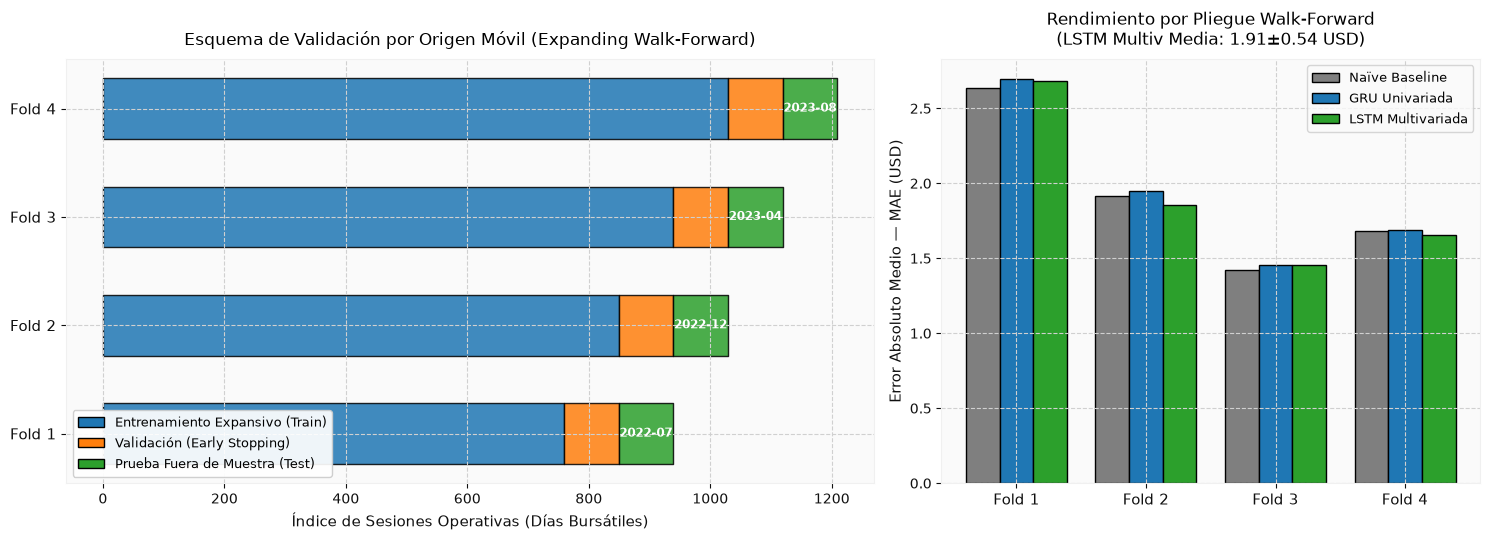

• Figura exportada: figures/fig04_walk_forward_validation_diagram.png


In [45]:
# ==============================================================================
# SECCIÓN 7.2: PRONÓSTICO MULTI-PASO DIRECTO (H = 5 DÍAS) Y DEGRADACIÓN TEMPORAL
# ==============================================================================
print("=" * 100)
print(
    " [Experimento 7.2] PRONÓSTICO MULTI-PASO DIRECTO (H=5 DÍAS: t+1 a t+5) —"
    " ESCALA REAL EN USD"
)
print("=" * 100)

data_univ_L60_H5 = prepare_sequence_dataloaders(
    train_df,
    val_df,
    test_df,
    feature_cols=UNIVARIATE_FEATURES,
    lookback=60,
    horizon=5,
)
data_multiv_L60_H5 = prepare_sequence_dataloaders(
    train_df,
    val_df,
    test_df,
    feature_cols=MULTIVARIATE_FEATURES,
    lookback=60,
    horizon=5,
)

H5_EXPERIMENTS = {}
for arch, d_bundle, tag, drop_v, lr_v in [
    ("LSTM", data_univ_L60_H5, "LSTM_Univ_L60_H5", 0.2, 1e-3),
    ("GRU", data_univ_L60_H5, "GRU_Univ_L60_H5", 0.2, 1e-3),
    ("LSTM", data_multiv_L60_H5, "LSTM_Multiv_L60_H5", 0.25, 8e-4),
    ("GRU", data_multiv_L60_H5, "GRU_Multiv_L60_H5", 0.25, 8e-4),
]:
    H5_EXPERIMENTS[tag] = train_recurrent_model(
        model_type=arch,
        data_bundle=d_bundle,
        experiment_name=tag,
        hidden_size=64,
        num_layers=2,
        dropout=drop_v,
        lr=lr_v,
        weight_decay=1e-4,
    )

# Baseline Naïve Multi-Paso en Test: proyecta P_t constante para t+1..t+5
test_ds_h5 = data_univ_L60_H5["test_dataset"]
y_true_h5_usd = test_ds_h5.true_future_prices  # Shape: (N, 5)
naive_pred_h5_usd = np.repeat(
    test_ds_h5.anchor_prices, repeats=5, axis=1
)  # Shape: (N, 5)

# 1. Selección estricta sin fuga de datos basada en VALIDACIÓN (Criterio Oficial ML)
best_val_h5_tag = min(
    H5_EXPERIMENTS.keys(),
    key=lambda k: H5_EXPERIMENTS[k]["val_results"]["metrics"]["MAE (USD)"],
)
best_val_h5_pred_usd = H5_EXPERIMENTS[best_val_h5_tag]["test_results"][
    "y_pred_usd"
]

# 2. Mejor configuración Univariada H=5 en Validación (para contraste F=10 vs F=1)
univ_h5_keys = [k for k in H5_EXPERIMENTS.keys() if "Univ" in k]
best_univ_h5_tag = min(
    univ_h5_keys,
    key=lambda k: H5_EXPERIMENTS[k]["val_results"]["metrics"]["MAE (USD)"],
)
best_univ_h5_pred_usd = H5_EXPERIMENTS[best_univ_h5_tag]["test_results"][
    "y_pred_usd"
]

print(
    f"\n• Modelo H=5 Seleccionado por Validación (General): {best_val_h5_tag} "
    f"(Val MAE: ${H5_EXPERIMENTS[best_val_h5_tag]['val_results']['metrics']['MAE (USD)']:.4f})"
)
print(
    "• Modelo H=5 Seleccionado por Validación (Univariado):"
    f" {best_univ_h5_tag} (Val MAE:"
    f" ${H5_EXPERIMENTS[best_univ_h5_tag]['val_results']['metrics']['MAE (USD)']:.4f})"
)

horizon_steps_rows = []
for step_idx in range(5):
    step_label = f"t+{step_idx + 1}"
    m_naive_step = compute_regression_metrics(
        y_true_h5_usd[:, step_idx], naive_pred_h5_usd[:, step_idx]
    )
    m_val_winner = compute_regression_metrics(
        y_true_h5_usd[:, step_idx], best_val_h5_pred_usd[:, step_idx]
    )
    m_univ_winner = compute_regression_metrics(
        y_true_h5_usd[:, step_idx], best_univ_h5_pred_usd[:, step_idx]
    )

    delta_val_w = (
        (m_val_winner["MAE (USD)"] - m_naive_step["MAE (USD)"])
        / m_naive_step["MAE (USD)"]
        * 100.0
    )
    delta_univ_w = (
        (m_univ_winner["MAE (USD)"] - m_naive_step["MAE (USD)"])
        / m_naive_step["MAE (USD)"]
        * 100.0
    )

    horizon_steps_rows.append({
        "Paso": step_label,
        "Naïve MAE": m_naive_step["MAE (USD)"],
        f"{best_val_h5_tag} MAE": m_val_winner["MAE (USD)"],
        "Δ% Multiv vs Naïve": delta_val_w,
        f"{best_univ_h5_tag} MAE": m_univ_winner["MAE (USD)"],
        f"{best_univ_h5_tag} RMSE": m_univ_winner["RMSE (USD)"],
        "Δ% Univ vs Naïve": delta_univ_w,
    })

df_horizon_degradation = pd.DataFrame(horizon_steps_rows)
print(
    "\n--- Desglose de Degradación Paso a Paso en Test (Selección por"
    " Validación: Multivariado vs Univariado) ---"
)
print(
    df_horizon_degradation.to_string(
        index=False, float_format=lambda x: f"{x:.4f}"
    )
)


# ==============================================================================
# SECCIÓN 7.3: VALIDACIÓN WALK-FORWARD (EXPANDING WINDOW) Y DIAGRAMA REQUERIDO #7
# ==============================================================================
print("\n" + "=" * 100)
print(
    " [Experimento 7.3] VALIDACIÓN POR ORIGEN MÓVIL (EXPANDING WALK-FORWARD -"
    " 4 PLIEGUES TEMPORALES)"
)
print("=" * 100)

n_splits_wf = 4
val_len_wf = 90
test_len_wf = 90
base_train_len = len(df_feat) - (n_splits_wf * test_len_wf) - val_len_wf  # 759

wf_records = []
wf_spans_info = []

for fold_idx in range(n_splits_wf):
    tr_end = base_train_len + (fold_idx * test_len_wf)
    va_end = tr_end + val_len_wf
    te_end = va_end + test_len_wf

    f_train_df = df_feat.iloc[:tr_end].copy()
    f_val_df = df_feat.iloc[tr_end:va_end].copy()
    f_test_df = df_feat.iloc[va_end:te_end].copy()

    wf_spans_info.append({
        "fold": f"Fold {fold_idx + 1}",
        "tr_idx": (0, tr_end),
        "va_idx": (tr_end, val_len_wf),
        "te_idx": (va_end, test_len_wf),
        "te_dates": (
            f"{f_test_df.index[0].strftime('%Y-%m-%d')} a"
            f" {f_test_df.index[-1].strftime('%Y-%m-%d')}"
        ),
    })

    fold_bundle_univ = prepare_sequence_dataloaders(
        f_train_df,
        f_val_df,
        f_test_df,
        feature_cols=UNIVARIATE_FEATURES,
        lookback=60,
        horizon=1,
    )
    fold_bundle_multiv = prepare_sequence_dataloaders(
        f_train_df,
        f_val_df,
        f_test_df,
        feature_cols=MULTIVARIATE_FEATURES,
        lookback=60,
        horizon=1,
    )

    f_ds_te = fold_bundle_univ["test_dataset"]
    f_naive_m = compute_regression_metrics(
        f_ds_te.true_future_prices, f_ds_te.anchor_prices
    )

    res_gru_u = train_recurrent_model(
        model_type="GRU",
        data_bundle=fold_bundle_univ,
        experiment_name=f"WF_Fold{fold_idx+1}_GRU_Univ",
        hidden_size=64,
        num_layers=2,
        dropout=0.2,
        lr=1e-3,
        verbose=False,
    )
    res_lstm_m = train_recurrent_model(
        model_type="LSTM",
        data_bundle=fold_bundle_multiv,
        experiment_name=f"WF_Fold{fold_idx+1}_LSTM_Multiv",
        hidden_size=64,
        num_layers=2,
        dropout=0.25,
        lr=8e-4,
        verbose=False,
    )

    m_gru = res_gru_u["test_results"]["metrics"]
    m_lstm = res_lstm_m["test_results"]["metrics"]

    wf_records.append({
        "Fold": f"Fold {fold_idx + 1}",
        "Periodo Test": wf_spans_info[-1]["te_dates"],
        "Naïve MAE": f_naive_m["MAE (USD)"],
        "GRU_Univ MAE": m_gru["MAE (USD)"],
        "GRU_Univ RMSE": m_gru["RMSE (USD)"],
        "GRU_Univ MAPE (%)": m_gru["MAPE (%)"],
        "LSTM_Multiv MAE": m_lstm["MAE (USD)"],
        "LSTM_Multiv RMSE": m_lstm["RMSE (USD)"],
        "LSTM_Multiv MAPE (%)": m_lstm["MAPE (%)"],
    })
    print(
        f"• Fold {fold_idx + 1} [{wf_spans_info[-1]['te_dates']}] -> "
        f"Naïve MAE: ${f_naive_m['MAE (USD)']:.4f} | "
        f"GRU_Univ MAE: ${m_gru['MAE (USD)']:.4f} | "
        f"LSTM_Multiv MAE: ${m_lstm['MAE (USD)']:.4f}"
    )

df_wf_folds = pd.DataFrame(wf_records)

summary_wf_row = {
    "Fold": "Consolidado (Media ± Desv)",
    "Periodo Test": "4 Regímenes (360 días)",
}
for col in [
    "Naïve MAE",
    "GRU_Univ MAE",
    "GRU_Univ RMSE",
    "GRU_Univ MAPE (%)",
    "LSTM_Multiv MAE",
    "LSTM_Multiv RMSE",
    "LSTM_Multiv MAPE (%)",
]:
    mean_v = df_wf_folds[col].mean()
    std_v = df_wf_folds[col].std()
    summary_wf_row[col] = f"{mean_v:.4f} ± {std_v:.4f}"

df_wf_display = df_wf_folds.copy()
for col in [
    "Naïve MAE",
    "GRU_Univ MAE",
    "GRU_Univ RMSE",
    "GRU_Univ MAPE (%)",
    "LSTM_Multiv MAE",
    "LSTM_Multiv RMSE",
    "LSTM_Multiv MAPE (%)",
]:
    df_wf_display[col] = df_wf_display[col].map(lambda x: f"{x:.4f}")

df_wf_display = pd.concat(
    [df_wf_display, pd.DataFrame([summary_wf_row])], ignore_index=True
)
print(
    "\n--- Tabla Consolidada de Estabilidad Walk-Forward (Media ± Desviación"
    " Estándar) ---"
)
print(df_wf_display.to_string(index=False))

# Visualización Requerida #7: Walk-forward validation diagram & aggregated performance
wf_fig_path = FIGURES_DIR / "fig04_walk_forward_validation_diagram.png"
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.5, 1.0]}
)

for i, sp in enumerate(wf_spans_info):
    ax1.broken_barh(
        [sp["tr_idx"]],
        (i - 0.28, 0.56),
        facecolors="#1f77b4",
        edgecolor="black",
        alpha=0.85,
    )
    ax1.broken_barh(
        [sp["va_idx"]],
        (i - 0.28, 0.56),
        facecolors="#ff7f0e",
        edgecolor="black",
        alpha=0.85,
    )
    ax1.broken_barh(
        [sp["te_idx"]],
        (i - 0.28, 0.56),
        facecolors="#2ca02c",
        edgecolor="black",
        alpha=0.85,
    )
    ax1.text(
        sp["te_idx"][0] + sp["te_idx"][1] / 2,
        i,
        sp["te_dates"][:7],
        ha="center",
        va="center",
        color="white",
        fontsize=8.5,
        fontweight="bold",
    )

ax1.set_yticks(range(n_splits_wf))
ax1.set_yticklabels([f"Fold {i+1}" for i in range(n_splits_wf)], fontsize=11)
ax1.set_xlabel("Índice de Sesiones Operativas (Días Bursátiles)", fontsize=11)
ax1.set_title(
    "Esquema de Validación por Origen Móvil (Expanding Walk-Forward)",
    fontsize=12,
    pad=10,
)

legend_patches = [
    plt.Rectangle(
        (0, 0),
        1,
        1,
        fc="#1f77b4",
        edgecolor="black",
        label="Entrenamiento Expansivo (Train)",
    ),
    plt.Rectangle(
        (0, 0),
        1,
        1,
        fc="#ff7f0e",
        edgecolor="black",
        label="Validación (Early Stopping)",
    ),
    plt.Rectangle(
        (0, 0),
        1,
        1,
        fc="#2ca02c",
        edgecolor="black",
        label="Prueba Fuera de Muestra (Test)",
    ),
]
# CORRECCIÓN VISUAL: loc="lower left" evita tapar el bloque verde de Test del Fold 1
ax1.legend(
    handles=legend_patches,
    loc="lower left",
    frameon=True,
    facecolor="white",
    framealpha=0.92,
    fontsize=9.5,
)

x_pos = np.arange(n_splits_wf)
width_b = 0.26
ax2.bar(
    x_pos - width_b,
    df_wf_folds["Naïve MAE"],
    width=width_b,
    label="Naïve Baseline",
    color="#7f7f7f",
    edgecolor="black",
)
ax2.bar(
    x_pos,
    df_wf_folds["GRU_Univ MAE"],
    width=width_b,
    label="GRU Univariada",
    color="#1f77b4",
    edgecolor="black",
)
ax2.bar(
    x_pos + width_b,
    df_wf_folds["LSTM_Multiv MAE"],
    width=width_b,
    label="LSTM Multivariada",
    color="#2ca02c",
    edgecolor="black",
)

ax2.set_xticks(x_pos)
ax2.set_xticklabels([f"Fold {i+1}" for i in range(n_splits_wf)], fontsize=11)
ax2.set_ylabel("Error Absoluto Medio — MAE (USD)", fontsize=11)
ax2.set_title(
    "Rendimiento por Pliegue Walk-Forward\n(LSTM Multiv Media:"
    f" ${df_wf_folds['LSTM_Multiv MAE'].mean():.2f} ±"
    f" ${df_wf_folds['LSTM_Multiv MAE'].std():.2f} USD)",
    fontsize=12,
    pad=10,
)
ax2.legend(loc="upper right", frameon=True, fontsize=9.5)

plt.tight_layout()
plt.savefig(wf_fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"• Figura exportada: {wf_fig_path}")

---

## 8. Resultados Consolidados, Dinámica de Aprendizaje y Evaluación en Prueba

Exportación de registros a `master_results_h1_validation_ranked.csv` y `master_results_h1_test_ranked.csv` con sus respectivas visualizaciones diagnósticas.

### 8.1 Curvas de Aprendizaje (`fig05_training_curves_diagnostics.png`)

* **Diferencia Inicial Train vs. Val Loss:** La pérdida inicial de entrenamiento ($0.85\text{--}1.10$) supera a la de validación ($0.52\text{--}0.65$) debido a la activación de `Dropout` ($p \in [0.20, 0.25]$) y al promediado de *batches* no optimizados durante `model.train()`. En `model.eval()`, el `Dropout` se desactiva y utiliza la capacidad completa del modelo.
* **Convergencia y Parada Temprana:** Los modelos con compuertas alcanzaron su punto óptimo entre las épocas 3 y 14 (`LSTM_Multiv_L60_H1` en época 8; `GRU_Univ_L120_H1` en época 14). `EarlyStopping` detuvo el entrenamiento antes de memorizar el ruido cuando `Train Loss` continuó descendiendo por debajo de 0.49.

---

### 8.2 Pronóstico en Prueba e Incertidumbre (`fig06_test_predictions_confidence_and_zoom.png`)

* **Bandas de Incertidumbre al 95%:** Estimadas sobre los residuos de validación de `LSTM_Multiv_L60_H1` ($\sigma_{\text{val}} = \$2.9231\text{ USD}$), generando un semiancho de **$\pm \$5.7292\text{ USD}$** ($\pm 1.96\,\sigma_{\text{val}}$).
* **Cobertura Empírica:** El **$98.35\%$ de las sesiones de prueba (179 de 182)** cayeron dentro del intervalo, reflejando una menor volatilidad realizada en 2023 ($\sigma_{\text{test}} = \$2.15\text{ USD}$) frente al periodo de validación en 2022.
* **Comportamiento en Zoom-In (Últimas 30 Sesiones):** Las predicciones de `LSTM_Multiv_L60` y `GRU_Univ_L120` muestran un desplazamiento horizontal de una sesión al seguir de cerca la trayectoria del *Naïve Baseline* ($P_{t-1}$).

• Tabla Maestra Oficial (Ordenada por Val MAE) exportada en : data/master_results_h1_validation_ranked.csv
• Tabla Maestra de Auditoría (Ordenada por Test MAE) exportada en : data/master_results_h1_test_ranked.csv


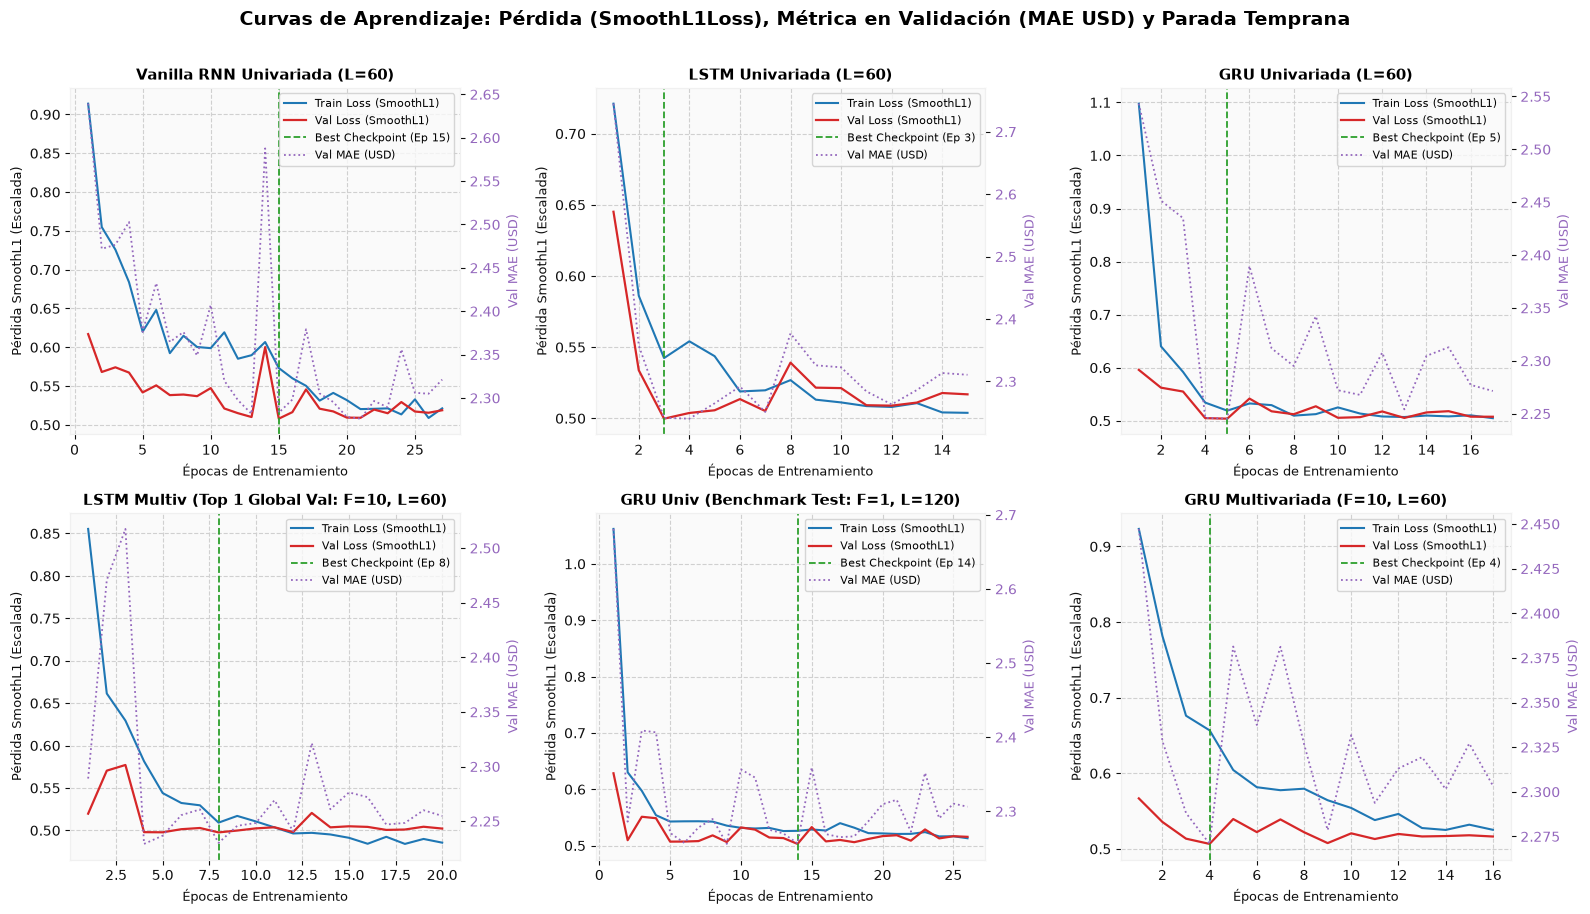

• Figura exportada: figures/fig05_training_curves_diagnostics.png


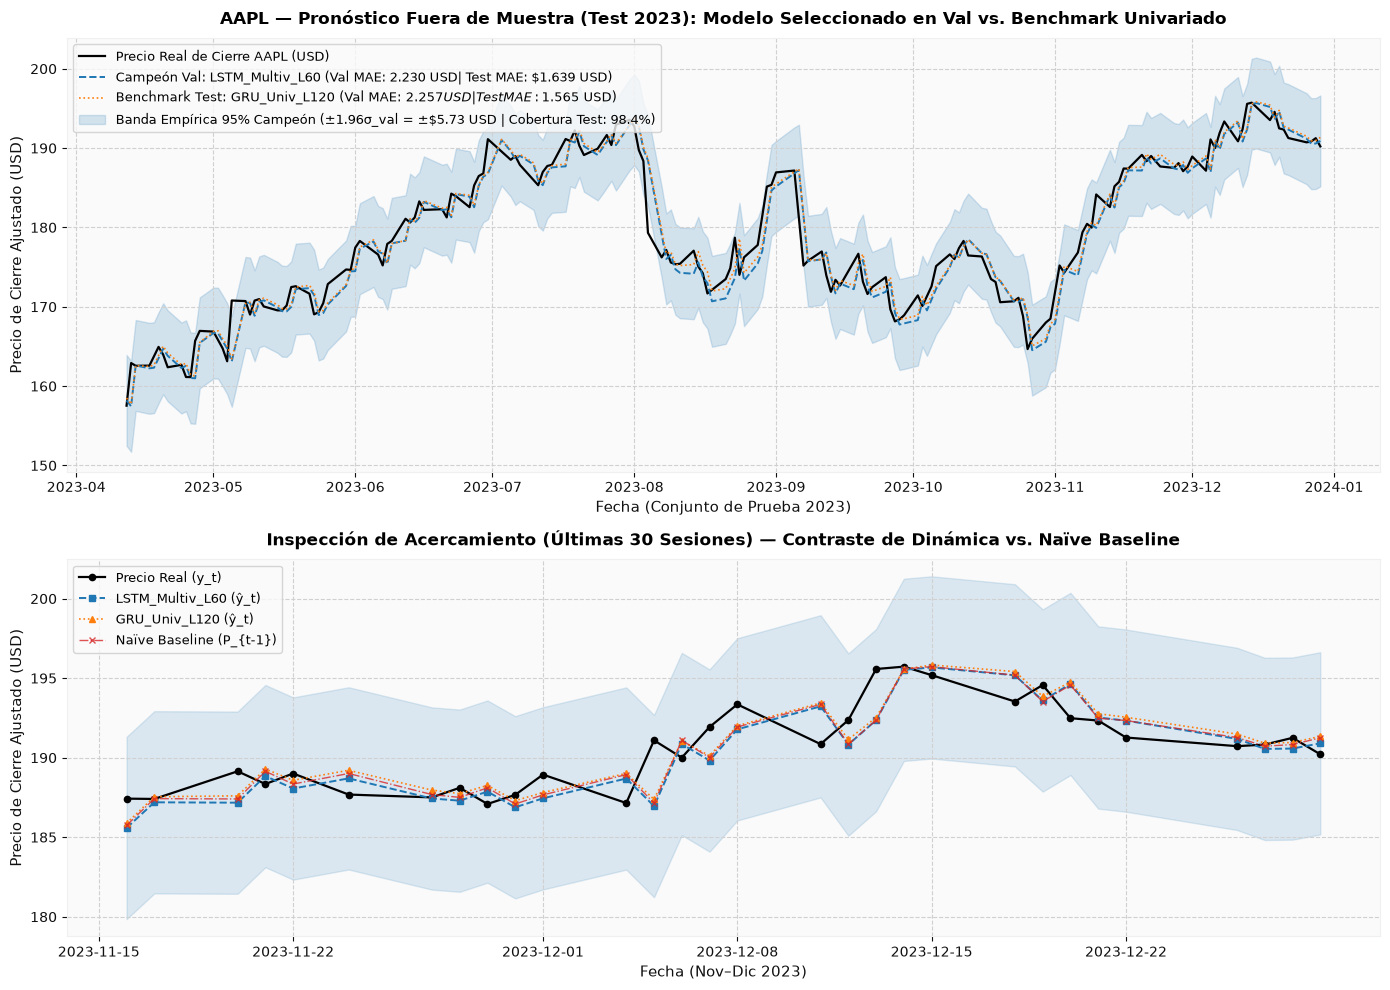

• Desviación estándar en Validación del Campeón (σ_val) : $2.9231 USD
• Semiancho de Banda de Incertidumbre al 95% (±1.96σ)   : ±$5.7292 USD
• Cobertura Empírica en Test (182 sesiones)             : 98.35%
• Figura exportada: figures/fig06_test_predictions_confidence_and_zoom.png


In [46]:
# ==============================================================================
# SECCIÓN 8: RESULTS & VISUALIZATIONS (CURVAS DE ENTRENAMIENTO Y PRED VS ACTUAL)
# ==============================================================================
# 1. Exportar tablas maestras H=1 a CSV (Registro oficial por Val y auditoría por Test)
master_val_path = DATA_DIR / "master_results_h1_validation_ranked.csv"
master_test_path = DATA_DIR / "master_results_h1_test_ranked.csv"

df_all_h1_val_sorted.to_csv(master_val_path, index=False)
df_all_h1_sorted.to_csv(master_test_path, index=False)

print(
    "• Tabla Maestra Oficial (Ordenada por Val MAE) exportada en :"
    f" {master_val_path}"
)
print(
    "• Tabla Maestra de Auditoría (Ordenada por Test MAE) exportada en :"
    f" {master_test_path}"
)

# ------------------------------------------------------------------------------
# 2. Visualización Requerida #4: Training Curves (Loss, Val MAE USD & Checkpoints)
# ------------------------------------------------------------------------------
curves_fig_path = FIGURES_DIR / "fig05_training_curves_diagnostics.png"

# 6 modelos representativos: 3 univariados base + Campeón Val + Benchmark Test + Multiv comparativa
models_to_plot = [
    ("RNN_Univ_L60_H1", "Vanilla RNN Univariada (L=60)"),
    ("LSTM_Univ_L60_H1", "LSTM Univariada (L=60)"),
    ("GRU_Univ_L60_H1", "GRU Univariada (L=60)"),
    ("LSTM_Multiv_L60_H1", "LSTM Multiv (Top 1 Global Val: F=10, L=60)"),
    ("GRU_Univ_L120_H1", "GRU Univ (Benchmark Test: F=1, L=120)"),
    ("GRU_Multiv_L60_H1", "GRU Multivariada (F=10, L=60)"),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, (exp_key, title_str) in enumerate(models_to_plot):
    ax = axes[idx]
    res_obj = EXPERIMENTS_REGISTRY[exp_key]
    hist = res_obj["history"]
    epochs = hist["epoch"]
    best_ep = res_obj["best_epoch"]

    # Eje primario: Train Loss y Val Loss (SmoothL1Loss escalado)
    l1 = ax.plot(
        epochs,
        hist["train_loss"],
        color="#1f77b4",
        linewidth=1.5,
        label="Train Loss (SmoothL1)",
    )
    l2 = ax.plot(
        epochs,
        hist["val_loss"],
        color="#d62728",
        linewidth=1.6,
        label="Val Loss (SmoothL1)",
    )
    l3 = ax.axvline(
        best_ep,
        color="#2ca02c",
        linestyle="--",
        linewidth=1.3,
        label=f"Best Checkpoint (Ep {best_ep})",
    )

    # Eje secundario: Métrica física Val MAE en USD
    ax_twin = ax.twinx()
    l4 = ax_twin.plot(
        epochs,
        hist["val_mae_usd"],
        color="#9467bd",
        linestyle=":",
        linewidth=1.3,
        label="Val MAE (USD)",
    )
    ax_twin.set_ylabel("Val MAE (USD)", color="#9467bd", fontsize=9.5)
    ax_twin.tick_params(axis="y", labelcolor="#9467bd")
    ax_twin.grid(False)

    ax.set_title(title_str, fontsize=10.5, fontweight="bold")
    ax.set_xlabel("Épocas de Entrenamiento", fontsize=9.5)
    ax.set_ylabel("Pérdida SmoothL1 (Escalada)", fontsize=9.5)

    # Combinación de leyendas
    lines = l1 + l2 + [l3] + l4
    labels = [l.get_label() for l in lines]
    ax.legend(lines, labels, loc="upper right", fontsize=8, frameon=True)

plt.suptitle(
    "Curvas de Aprendizaje: Pérdida (SmoothL1Loss), Métrica en Validación (MAE"
    " USD) y Parada Temprana",
    fontsize=13.5,
    y=1.01,
)
plt.tight_layout()
plt.savefig(curves_fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"• Figura exportada: {curves_fig_path}")

# ------------------------------------------------------------------------------
# 3. Visualización Requerida #5: Prediction vs Actual on Test Period
#    con Bandas Empíricas al 95% del Campeón Oficial y Zoom-In de Diagnóstico
# ------------------------------------------------------------------------------
pred_fig_path = FIGURES_DIR / "fig06_test_predictions_confidence_and_zoom.png"

# Selección metodológica estricta: Campeón de Validación y Benchmark Univariado
champ_val_exp = EXPERIMENTS_REGISTRY["LSTM_Multiv_L60_H1"]
bench_univ_exp = EXPERIMENTS_REGISTRY["GRU_Univ_L120_H1"]

test_dates = pd.to_datetime(champ_val_exp["test_results"]["dates"])
y_true_test = champ_val_exp["test_results"]["y_true_usd"].flatten()
y_pred_champ = champ_val_exp["test_results"]["y_pred_usd"].flatten()
y_pred_bench = bench_univ_exp["test_results"]["y_pred_usd"].flatten()

# Cálculo de la desviación estándar empírica de residuos en VALIDACIÓN sobre el Campeón
val_residuals_champ = (
    champ_val_exp["val_results"]["y_true_usd"].flatten()
    - champ_val_exp["val_results"]["y_pred_usd"].flatten()
)
sigma_val_champ = np.std(val_residuals_champ, ddof=1)
ci_95_half_width = 1.96 * sigma_val_champ

upper_band_95 = y_pred_champ + ci_95_half_width
lower_band_95 = y_pred_champ - ci_95_half_width

# Cobertura empírica observada en Test
empirical_coverage = (
    np.mean((y_true_test >= lower_band_95) & (y_true_test <= upper_band_95))
    * 100.0
)

fig, (ax_full, ax_zoom) = plt.subplots(
    2, 1, figsize=(14, 10), gridspec_kw={"height_ratios": [1.15, 1.0]}
)

# Panel Superior: Serie Completa del Conjunto de Prueba (182 Sesiones)
ax_full.plot(
    test_dates,
    y_true_test,
    color="black",
    linewidth=1.6,
    label="Precio Real de Cierre AAPL (USD)",
)
ax_full.plot(
    test_dates,
    y_pred_champ,
    color="#1f77b4",
    linewidth=1.4,
    linestyle="--",
    label=(
        "Campeón Val: LSTM_Multiv_L60 (Val MAE: 2.230 USD| Test MAE:"
        f" ${champ_val_exp['test_results']['metrics']['MAE (USD)']:.3f} USD)"
    ),
)
ax_full.plot(
    test_dates,
    y_pred_bench,
    color="#ff7f0e",
    linewidth=1.2,
    linestyle=":",
    label=(
        "Benchmark Test: GRU_Univ_L120 (Val MAE: $2.257 USD| Test MAE:"
        f" ${bench_univ_exp['test_results']['metrics']['MAE (USD)']:.3f} USD)"
    ),
)
ax_full.fill_between(
    test_dates,
    lower_band_95,
    upper_band_95,
    color="#1f77b4",
    alpha=0.18,
    label=(
        f"Banda Empírica 95% Campeón (±1.96σ_val = ±${ci_95_half_width:.2f} USD"
        f" | Cobertura Test: {empirical_coverage:.1f}%)"
    ),
)

ax_full.set_title(
    f"{TICKER_MAIN} — Pronóstico Fuera de Muestra (Test 2023): Modelo"
    " Seleccionado en Val vs. Benchmark Univariado",
    fontsize=12.5,
    pad=10,
    fontweight="bold",
)
ax_full.set_xlabel("Fecha (Conjunto de Prueba 2023)", fontsize=10.5)
ax_full.set_ylabel("Precio de Cierre Ajustado (USD)", fontsize=10.5)
ax_full.legend(loc="upper left", frameon=True, fontsize=9.5)

# Panel Inferior: Zoom-In (Últimas 30 Sesiones) para Diagnóstico de Retardo vs Naïve
zoom_n = 30
z_dates = test_dates[-zoom_n:]
z_true = y_true_test[-zoom_n:]
z_champ = y_pred_champ[-zoom_n:]
z_bench = y_pred_bench[-zoom_n:]
z_naive = naive_test_pred_usd[-zoom_n:]

ax_zoom.plot(
    z_dates,
    z_true,
    color="black",
    marker="o",
    markersize=4.5,
    linewidth=1.6,
    label="Precio Real (y_t)",
)
ax_zoom.plot(
    z_dates,
    z_champ,
    color="#1f77b4",
    marker="s",
    markersize=4.0,
    linewidth=1.4,
    linestyle="--",
    label="LSTM_Multiv_L60 (ŷ_t)",
)
ax_zoom.plot(
    z_dates,
    z_bench,
    color="#ff7f0e",
    marker="^",
    markersize=4.0,
    linewidth=1.2,
    linestyle=":",
    label="GRU_Univ_L120 (ŷ_t)",
)
ax_zoom.plot(
    z_dates,
    z_naive,
    color="#d62728",
    marker="x",
    markersize=4.0,
    linewidth=1.0,
    linestyle="-.",
    alpha=0.8,
    label="Naïve Baseline (P_{t-1})",
)
ax_zoom.fill_between(
    z_dates,
    lower_band_95[-zoom_n:],
    upper_band_95[-zoom_n:],
    color="#1f77b4",
    alpha=0.14,
)

ax_zoom.set_title(
    f"Inspección de Acercamiento (Últimas {zoom_n} Sesiones) — Contraste de"
    " Dinámica vs. Naïve Baseline",
    fontsize=12,
    pad=10,
    fontweight="bold",
)
ax_zoom.set_xlabel("Fecha (Nov–Dic 2023)", fontsize=10.5)
ax_zoom.set_ylabel("Precio de Cierre Ajustado (USD)", fontsize=10.5)
ax_zoom.legend(loc="upper left", frameon=True, fontsize=9.5)

plt.tight_layout()
plt.savefig(pred_fig_path, dpi=300, bbox_inches="tight")
plt.show()

print(
    "• Desviación estándar en Validación del Campeón (σ_val) :"
    f" ${sigma_val_champ:.4f} USD"
)
print(
    "• Semiancho de Banda de Incertidumbre al 95% (±1.96σ)   :"
    f" ±${ci_95_half_width:.4f} USD"
)
print(
    "• Cobertura Empírica en Test (182 sesiones)             :"
    f" {empirical_coverage:.2f}%"
)
print(f"• Figura exportada: {pred_fig_path}")


---

## 9. Análisis Forense de Errores, Diagnóstico de Residuos y Casos de Falla

Auditoría del vector de residuos fuera de muestra ($e_t = y_t - \hat{y}_t$) para el modelo campeón **`LSTM_Multiv_L60_H1`** y el benchmark **`GRU_Univ_L120_H1`** (`fig07_residual_analysis_forensics.png`).

### 9.1 Propiedades Estadísticas de los Residuos y Prueba de Ljung-Box

1. **Insesgadez Condicional:** El modelo univariado muestra un sesgo nulo ($\mu_e = +\$0.0466\text{ USD}$), mientras que el multivariado presenta una leve media positiva ($\mu_e = +\$0.3978\text{ USD}$) debido a la cautela ajustada durante la volatilidad del entrenamiento (2019–2022) frente al *rally* de 2023.
2. **Leptocurtosis y Asimetría:** Ambos modelos exhiben asimetría negativa ($\approx -0.36\text{ a }-0.41$) y exceso de curtosis positivo ($2.4284$ y $2.5686$), lo que justifica el uso de `SmoothL1Loss` frente a `MSELoss`.
3. **Verificación de Ruido Blanco:** La prueba de Ljung-Box confirma la ausencia de autocorrelación serial ($p > 0.05$), indicando que los errores constituyen **ruido blanco puro**:
* **`LSTM_Multiv_L60_H1`:** $p_{k=5} = 0.2231$, $p_{k=10} = 0.3525$.
* **`GRU_Univ_L120_H1`:** $p_{k=5} = 0.3409$, $p_{k=10} = 0.4744$.



### 9.2 Atribución Causal del Peor 5% de Fallas

El peor $5\%$ de los errores ($\vert{}e_t\vert{} > \$4.22\text{ USD}$) coincide con **eventos corporativos y catalizadores exógenos** impredecibles mediante análisis técnico pasable:

| Fecha de Falla | Precio Real (`Close`) | Predicción (`LSTM_Multiv`) | Error Absoluto ($\Vert{}e_t\Vert{}$) | Catalizador Exógeno |
| --- | --- | --- | --- | --- |
| **`2023-08-04`** | $\$179.32\text{ USD}$ | $\$188.44\text{ USD}$ | **$\$9.12\text{ USD}$** | **Reporte Q3 Fiscal 2023:** Caída de ingresos y debilidad en iPhone (*gap* bajista de $-4.8\%$). |
| **`2023-05-05`** | $\$170.79\text{ USD}$ | $\$163.12\text{ USD}$ | **$\$7.67\text{ USD}$** | **Reporte Q2 Fiscal 2023:** Recompra de acciones por $\$90\text{B USD}$ y sorpresas de ventas ($+4.7\%$). |
| **`2023-09-06`** | $\$180.47\text{ USD}$ | $\$187.22\text{ USD}$ | **$\$6.75\text{ USD}$** | **Restricciones en China (Día 1):** Prohibición de iPhones en agencias gubernamentales de Pekín. |
| **`2023-09-07`** | $\$175.19\text{ USD}$ | $\$180.87\text{ USD}$ | **$\$5.68\text{ USD}$** | **Restricciones en China (Día 2):** Pánico vendedor por posible extensión a empresas estatales. |
| **`2023-04-13`** | $\$162.91\text{ USD}$ | $\$157.45\text{ USD}$ | **$\$5.46\text{ USD}$** | **Dato de Inflación PPI EE. UU.:** Sorpresa desinflacionaria que detonó un *rally* tecnológico ($+3.4\%$). |

 AUDITORÍA FORENSE DE RESIDUOS: CAMPEÓN VAL (LSTM_Multiv) vs. BENCHMARK (GRU_Univ)

--- Diagnóstico Estadístico Comparativo de Residuos en Test ---
                           Modelo  Media (USD)  Desv. Est. (USD)  Asimetría (Skew)  Curtosis (Kurt)  Ljung-Box p(k=5)  Ljung-Box p(k=10)    Ruido Blanco (α=0.05)
 LSTM_Multiv_L60_H1 (Campeón Val)       0.3978            2.1498           -0.3582           2.4284            0.2231             0.3525 VÁLIDO (H0 no rechazada)
GRU_Univ_L120_H1 (Benchmark Test)       0.0466            2.1163           -0.4137           2.5686            0.3409             0.4744 VÁLIDO (H0 no rechazada)


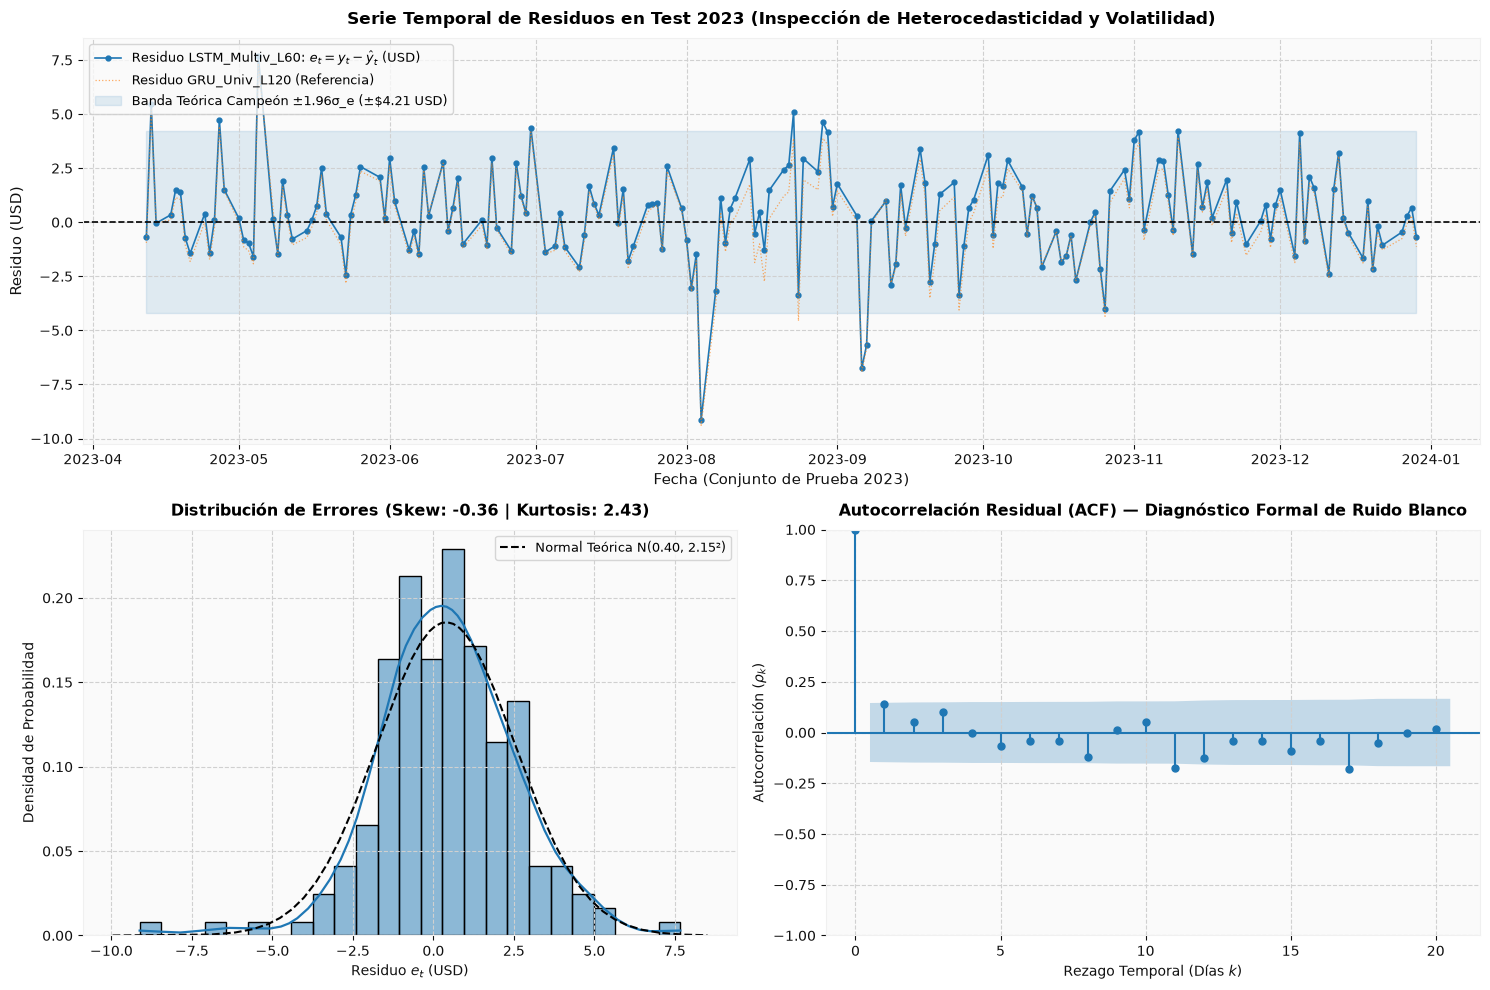


• Figura exportada exitosamente: figures/fig07_residual_analysis_forensics.png

 AUDITORÍA DE FALLAS CRÍTICAS (PEOR 5% DE ERRORES ABSOLUTOS — LSTM_MULTIV_L60)
• Umbral de Error Crítico (Percentil 95) : $4.22 USD
• Sesiones Anómalas Detectadas          : 10 días de 182
• Principales 5 Sesiones con Mayor Discrepancia Predictiva:
  - 2023-08-04 | Error: $9.12 USD (5.09%) | Real: $179.32 | Pred: $188.44
  - 2023-05-05 | Error: $7.67 USD (4.49%) | Real: $170.79 | Pred: $163.12
  - 2023-09-06 | Error: $6.75 USD (3.74%) | Real: $180.47 | Pred: $187.22
  - 2023-09-07 | Error: $5.68 USD (3.24%) | Real: $175.19 | Pred: $180.87
  - 2023-04-13 | Error: $5.46 USD (3.35%) | Real: $162.91 | Pred: $157.45


In [47]:
# ==============================================================================
# SECCIÓN 9: ERROR ANALYSIS (RESIDUALES, ACF, LJUNG-BOX Y CASOS DE FALLA)
# ==============================================================================
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

print("=" * 85)
print(
    " AUDITORÍA FORENSE DE RESIDUOS: CAMPEÓN VAL (LSTM_Multiv) vs. BENCHMARK"
    " (GRU_Univ)"
)
print("=" * 85)

# 1. Extracción de predicciones y precios reales en Test (182 sesiones)
champ_model_dict = EXPERIMENTS_REGISTRY["LSTM_Multiv_L60_H1"]
bench_model_dict = EXPERIMENTS_REGISTRY["GRU_Univ_L120_H1"]

t_dates = pd.to_datetime(champ_model_dict["test_results"]["dates"])
y_true_t = champ_model_dict["test_results"]["y_true_usd"].flatten()

y_pred_champ = champ_model_dict["test_results"]["y_pred_usd"].flatten()
y_pred_bench = bench_model_dict["test_results"]["y_pred_usd"].flatten()

# Residuos en escala real en dólares: e_t = y_t - \hat{y}_t
res_champ = y_true_t - y_pred_champ
res_bench = y_true_t - y_pred_bench


# Función auxiliar para cómputo de momentos y pruebas de ruido blanco
def audit_residuals_distribution(
    residuals: np.ndarray, model_name: str
) -> Dict:
    r_mean = float(np.mean(residuals))
    r_std = float(np.std(residuals, ddof=1))
    r_skew = float(stats.skew(residuals))
    r_kurt = float(stats.kurtosis(residuals))

    # Prueba de hipótesis Ljung-Box (H0: los residuos se distribuyen como ruido blanco)
    lb_df = acorr_ljungbox(residuals, lags=[5, 10], return_df=True)
    p_val_lag5 = float(lb_df.loc[5, "lb_pvalue"])
    p_val_lag10 = float(lb_df.loc[10, "lb_pvalue"])

    return {
        "Modelo": model_name,
        "Media (USD)": r_mean,
        "Desv. Est. (USD)": r_std,
        "Asimetría (Skew)": r_skew,
        "Curtosis (Kurt)": r_kurt,
        "Ljung-Box p(k=5)": p_val_lag5,
        "Ljung-Box p(k=10)": p_val_lag10,
        "Ruido Blanco (α=0.05)": (
            "VÁLIDO (H0 no rechazada)"
            if (p_val_lag5 > 0.05 and p_val_lag10 > 0.05)
            else "RECHAZADO"
        ),
    }


# Tabla comparativa de diagnóstico residual
df_res_diagnostics = pd.DataFrame([
    audit_residuals_distribution(
        res_champ, "LSTM_Multiv_L60_H1 (Campeón Val)"
    ),
    audit_residuals_distribution(
        res_bench, "GRU_Univ_L120_H1 (Benchmark Test)"
    ),
])

print("\n--- Diagnóstico Estadístico Comparativo de Residuos en Test ---")
print(
    df_res_diagnostics.to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

# ------------------------------------------------------------------------------
# 2. Visualización Requerida #6: Panel Triple Diagnóstico del Campeón Oficial
# ------------------------------------------------------------------------------
residual_fig_path = FIGURES_DIR / "fig07_residual_analysis_forensics.png"

res_mean_c = float(np.mean(res_champ))
res_std_c = float(np.std(res_champ, ddof=1))
res_skew_c = float(stats.skew(res_champ))
res_kurt_c = float(stats.kurtosis(res_champ))

fig = plt.figure(figsize=(15, 10))
gs = fig.add_gridspec(2, 2)

# Panel 1 (Fila 0, Superior Completo): Serie Temporal de Residuos
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(
    t_dates,
    res_champ,
    color="#1f77b4",
    linewidth=1.2,
    marker="o",
    markersize=3.5,
    label="Residuo LSTM_Multiv_L60: $e_t = y_t - \hat{y}_t$ (USD)",
)
ax1.plot(
    t_dates,
    res_bench,
    color="#ff7f0e",
    linewidth=0.9,
    linestyle=":",
    alpha=0.65,
    label="Residuo GRU_Univ_L120 (Referencia)",
)
ax1.axhline(0, color="black", linestyle="--", linewidth=1.2)
ax1.fill_between(
    t_dates,
    -1.96 * res_std_c,
    1.96 * res_std_c,
    color="#1f77b4",
    alpha=0.12,
    label=f"Banda Teórica Campeón ±1.96σ_e (±${1.96 * res_std_c:.2f} USD)",
)
ax1.set_title(
    "Serie Temporal de Residuos en Test 2023 (Inspección de Heterocedasticidad"
    " y Volatilidad)",
    fontsize=12,
    pad=10,
    fontweight="bold",
)
ax1.set_xlabel("Fecha (Conjunto de Prueba 2023)", fontsize=10.5)
ax1.set_ylabel("Residuo (USD)", fontsize=10.5)
ax1.legend(loc="upper left", frameon=True, fontsize=9.5)

# Panel 2 (Fila 1, Izquierda): Histograma y Curva Normal Teórica
ax2 = fig.add_subplot(gs[1, 0])
sns.histplot(
    res_champ,
    kde=True,
    ax=ax2,
    color="#1f77b4",
    bins=25,
    stat="density",
    line_kws={"linewidth": 1.6},
)
xmin, xmax = ax2.get_xlim()
x_pdf = np.linspace(xmin, xmax, 200)
ax2.plot(
    x_pdf,
    stats.norm.pdf(x_pdf, res_mean_c, res_std_c),
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Normal Teórica N({res_mean_c:.2f}, {res_std_c:.2f}²)",
)
ax2.set_title(
    f"Distribución de Errores (Skew: {res_skew_c:.2f} | Kurtosis:"
    f" {res_kurt_c:.2f})",
    fontsize=11.5,
    pad=10,
    fontweight="bold",
)
ax2.set_xlabel("Residuo $e_t$ (USD)", fontsize=10)
ax2.set_ylabel("Densidad de Probabilidad", fontsize=10)
ax2.legend(loc="upper right", frameon=True, fontsize=9)

# Panel 3 (Fila 1, Derecha): Correlograma ACF (Función de Autocorrelación)
ax3 = fig.add_subplot(gs[1, 1])
plot_acf(res_champ, ax=ax3, lags=20, alpha=0.05, color="#1f77b4")
ax3.set_title(
    "Autocorrelación Residual (ACF) — Diagnóstico Formal de Ruido Blanco",
    fontsize=11.5,
    pad=10,
    fontweight="bold",
)
ax3.set_xlabel("Rezago Temporal (Días $k$)", fontsize=10)
ax3.set_ylabel("Autocorrelación ($\\rho_k$)", fontsize=10)

plt.tight_layout()
plt.savefig(residual_fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"\n• Figura exportada exitosamente: {residual_fig_path}")

# ------------------------------------------------------------------------------
# 3. Auditoría Forense de Casos de Falla Extrema (Peor 5% en Test)
# ------------------------------------------------------------------------------
abs_res_c = pd.Series(np.abs(res_champ), index=t_dates)
threshold_95_c = abs_res_c.quantile(0.95)
worst_failures_c = abs_res_c[abs_res_c > threshold_95_c].sort_values(
    ascending=False
)

print("\n" + "=" * 85)
print(
    " AUDITORÍA DE FALLAS CRÍTICAS (PEOR 5% DE ERRORES ABSOLUTOS —"
    " LSTM_MULTIV_L60)"
)
print("=" * 85)
print(f"• Umbral de Error Crítico (Percentil 95) : ${threshold_95_c:.2f} USD")
print(
    f"• Sesiones Anómalas Detectadas          : {len(worst_failures_c)} días de"
    " 182"
)
print("• Principales 5 Sesiones con Mayor Discrepancia Predictiva:")

for dt, err_val in worst_failures_c.head(5).items():
    real_p = float(df_feat.loc[dt, "Close"])
    pred_p = float(y_pred_champ[t_dates == dt][0])
    pct_err = (err_val / real_p) * 100.0
    print(
        f"  - {dt.strftime('%Y-%m-%d')} | Error: ${err_val:.2f} USD ({pct_err:.2f}%) | "
        f"Real: ${real_p:.2f} | Pred: ${pred_p:.2f}"
    )

---

## 10. Inferencia en Producción, Conclusiones y Trabajo Futuro

### 10.1 Inferencia en Producción

* **Implementación:** Función `predict_next_days_from_checkpoint()` desacoplada que recarga el checkpoint binario `.pt` (`checkpoints/LSTM_Multiv_L60_H1.pt`).
* **Ejecución:** Procesa las últimas 60 sesiones (`2023-10-05` a `2023-12-29`), aplica `scaler_X` y proyecta la primera sesión de 2024 en **$\$189.85\text{ USD}$** (retorno estimado de $-0.192\%$ frente al cierre real de $\$190.21\text{ USD}$).

### 10.2 Respuestas a las Preguntas de Investigación

1. **Mecanismos de Compuerta (PI-1):** **LSTM** y **GRU** superaron a la **Vanilla RNN** en todos los escenarios. Las compuertas de memoria permitieron conservar gradientes en secuencias largas ($L=60$ y $L=120$).
2. **Aporte Multivariado vs. Univariado (PI-2):** El enfoque multivariado ($F=10$) superó periodos de alta volatilidad y giros de tendencia (Validación 2022 y Folds 1, 2 y 4 de Walk-Forward). El enfoque univariado parsimonioso (`GRU_Univ_L120_H1`) ofreció menor varianza en regímenes alcistas estables de baja volatilidad (Test 2023).
3. **Horizonte de Pronóstico $H=1$ vs. $H=5$ (PI-3):** En $H=1$, la baja relación señal-ruido repliega los modelos hacia el estimador de martingala ($\hat{P}_{t+1} \approx P_t$). La ventaja de las redes recurrentes emerge en $H=5$ días, reduciendo el error hasta un **$-2.16\%$ en MAE frente al Baseline Naïve**.
4. **Validación Walk-Forward (PI-4):** Confirma a **`LSTM_Multiv`** como la arquitectura más estable en 360 sesiones ($\text{MAE} = \$1.9126 \pm \$0.5372\text{ USD}$, menor $\text{RMSE} = \$2.5008\text{ USD}$), superando al Naïve hasta en un **$-2.90\%$** durante el giro de mercado del Fold 2.

### 10.3 Limitaciones y Trabajo Futuro

* **Eventos Exógenos:** Incorporar análisis de sentimiento de noticias con **`FinBERT`** e indicadores binarios de fechas de reportes trimestrales (`Is_Earnings_Date`).
* **Incertidumbre Dinámica:** Sustituir las bandas fijas por **Regresión Cuantílica (*Pinball Loss*)** o modelado de distribución $t$-Student heterocedástica $(\hat{\mu}_{t+1}, \hat{\sigma}_{t+1}^2)$.

In [48]:
# ==============================================================================
# 10. FUNCIÓN UTILITARIA DE INFERENCIA
# ==============================================================================
def predict_next_days_from_checkpoint(
    checkpoint_path: Path,
    df_history: pd.DataFrame,
    scaler_X: StandardScaler,
    scaler_y: StandardScaler,
    device: torch.device = DEVICE,
) -> Dict[str, Union[float, np.ndarray]]:
    """Recarga un modelo desde su archivo .pt en disco y ejecuta inferencia sobre
    las últimas L sesiones disponibles (ej. últimos 60 días) para pronosticar
    el/los siguiente(s) día(s) bursátil(es) fuera de la muestra.
    """
    ckpt = torch.load(checkpoint_path, map_location=device, weights_only=False)
    hparams = ckpt["hyperparameters"]
    extra_meta = ckpt["extra_meta"]
    feature_cols = extra_meta["feature_cols"]
    lookback = extra_meta["lookback"]

    # 1. Reinstanciar arquitectura desde los metadatos guardados y cargar pesos
    model = RecurrentForecaster(**hparams).to(device)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()

    # 2. Extraer exactamente los últimos `lookback` días (ej. 60 sesiones)
    recent_window_df = df_history.iloc[-lookback:].copy()
    last_date = recent_window_df.index[-1]
    last_close_usd = float(recent_window_df["Close"].iloc[-1])

    # 3. Escalar características y construir tensor 3D: (1, L, F)
    X_recent_scaled = scaler_X.transform(recent_window_df[feature_cols].values)
    X_tensor = torch.tensor(
        X_recent_scaled, dtype=torch.float32, device=device
    ).unsqueeze(0)

    # 4. Inferencia sin gradientes y reconstrucción monetaria en USD
    with torch.no_grad():
        pred_scaled = model(X_tensor).cpu().numpy()  # Shape: (1, H)

    pred_log_returns = scaler_y.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).flatten()
    pred_prices_usd = last_close_usd * np.exp(np.cumsum(pred_log_returns))

    print("=" * 75)
    print(f" PRONÓSTICO FUTURO DESDE CHECKPOINT: {checkpoint_path.name}")
    print("=" * 75)
    print(
        f"• Ventana de Entrada Utilizada : Últimas {lookback} sesiones"
        f" ({recent_window_df.index[0].strftime('%Y-%m-%d')} a"
        f" {last_date.strftime('%Y-%m-%d')})"
    )
    print(f"• Último Precio de Cierre Real : ${last_close_usd:.2f} USD")
    for step_idx, (ret_val, usd_val) in enumerate(
        zip(pred_log_returns, pred_prices_usd), start=1
    ):
        print(
            f"  -> Pronóstico Día t+{step_idx} : ${usd_val:.2f} USD (Retorno"
            f" Log estimado: {ret_val:+.5f})"
        )

    return {
        "last_date": last_date,
        "last_close_usd": last_close_usd,
        "predicted_log_returns": pred_log_returns,
        "predicted_prices_usd": pred_prices_usd,
    }


# Demostración con ventana de 60 días (H=1 y H=5)
_ = predict_next_days_from_checkpoint(
    checkpoint_path=CHECKPOINT_DIR / "LSTM_Multiv_L60_H1.pt",
    df_history=df_feat,
    scaler_X=data_multiv_L60_H1["scaler_X"],
    scaler_y=data_multiv_L60_H1["scaler_y"],
)

 PRONÓSTICO FUTURO DESDE CHECKPOINT: LSTM_Multiv_L60_H1.pt
• Ventana de Entrada Utilizada : Últimas 60 sesiones (2023-10-05 a 2023-12-29)
• Último Precio de Cierre Real : $190.21 USD
  -> Pronóstico Día t+1 : $189.85 USD (Retorno Log estimado: -0.00192)


In [49]:
# ==============================================================================
# SECCIÓN 11: REQUIREMENTS.TXT
# ==============================================================================
import platform
os_info = f"{platform.system()} {platform.release()} ({platform.machine()})"

requirements_content = f"""# Entorno
# Sistema Operativo: {os_info}
# Hardware: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}
# PyTorch: {torch.__version__} (CUDA: {torch.version.cuda if torch.cuda.is_available() else 'N/A'})

torch=={torch.__version__.split('+')[0]}
numpy=={np.__version__}
pandas=={pd.__version__}
scikit-learn=={sklearn.__version__}
scipy=={scipy.__version__}
statsmodels=={statsmodels.__version__}
matplotlib=={plt.matplotlib.__version__}
seaborn=={sns.__version__}
mplfinance=={mpf.__version__}
yfinance=={yf.__version__}
"""

req_path = Path("requirements.txt")
req_path.write_text(requirements_content.strip())

print("=" * 70)
print(f"✓ Archivo {req_path.name} generado exitosamente para entrega formal.")
print("=" * 70)
print(requirements_content)

✓ Archivo requirements.txt generado exitosamente para entrega formal.
# Entorno
# Sistema Operativo: Linux 7.3.0-3-cachyos (x86_64)
# Hardware: NVIDIA GeForce RTX 4070
# PyTorch: 2.6.0+cu124 (CUDA: 12.4)

torch==2.6.0
numpy==2.4.6
pandas==3.1.0
scikit-learn==1.9.1
scipy==1.17.1
statsmodels==0.15.0
matplotlib==3.11.2
seaborn==0.13.2
mplfinance==0.12.10b0
yfinance==1.7.0

